## Personalized Product Recommendations

### Objective
Recommend 10 articles that a customer may purchase next.

### Initial baseline
Recommend the 10 most frequently purchased articles during the
28 days preceding the prediction date.

### Evaluation design
- Prediction date: 31 December 2019.
- Popularity window: 4–31 December 2019.
- Outcome window: 1–7 January 2020.
- Eligible customers: customers with at least one purchase by the
  prediction date.

Recommendation relevance will be evaluated among eligible customers
who purchased during the outcome window. Each customer–article pair
will count once in the evaluation target.

In [1]:
import sys
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project folder whether this notebook runs from
# the project root or from the notebook subfolder.
current_folder = Path.cwd().resolve()

project_root = next(
    (
        folder
        for folder in [current_folder, *current_folder.parents]
        if (
            folder / "data" / "processed" / "transactions.parquet"
        ).is_file()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate data/processed/transactions.parquet. "
        "Open this notebook from your project folder."
    )

data_dir = project_root / "data" / "processed"
recommendation_report_dir = project_root / "reports" / "recommendations"
recommendation_report_dir.mkdir(parents=True, exist_ok=True)

source_files = {
    "transactions": data_dir / "transactions.parquet",
    "articles": data_dir / "articles.parquet",
}

for table_name, file_path in source_files.items():
    if not file_path.is_file():
        raise FileNotFoundError(f"Missing source file: {file_path}")

# Reuse the connection if this setup cell is rerun.
if "con" not in globals():
    con = duckdb.connect()

con.execute("SET memory_limit = '1GB'")
con.execute("SET threads = 2")

for table_name, file_path in source_files.items():
    sql_path = file_path.as_posix().replace("'", "''")

    con.execute(f"""
        CREATE OR REPLACE TEMP VIEW {table_name} AS
        SELECT * FROM read_parquet('{sql_path}')
    """)

print("Python:", sys.executable)
print("Project folder:", project_root)
print("DuckDB version:", duckdb.__version__)
print("Source views ready: transactions, articles")
print("Reports folder:", recommendation_report_dir)

Python: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\.venv\Scripts\python.exe
Project folder: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project
DuckDB version: 1.5.5
Source views ready: transactions, articles
Reports folder: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\recommendations


In [2]:
recommendation_cutoff = "2019-12-31"
popularity_window_days = 28
evaluation_window_days = 7
top_k = 10

# Check that the full evaluation window is covered.
coverage = con.execute(f"""
SELECT
    MIN(t_dat) AS first_available_date,
    MAX(t_dat) AS last_available_date,
    MAX(t_dat) >= (
        DATE '{recommendation_cutoff}'
        + INTERVAL {evaluation_window_days} DAY
    ) AS complete_outcome_window
FROM transactions
""").df()

display(coverage)

if not bool(coverage.loc[0, "complete_outcome_window"]):
    raise ValueError("The full recommendation evaluation week is unavailable.")

# Customers observed before or on the prediction date.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE recommendation_eligible_customers AS
SELECT DISTINCT customer_id
FROM transactions
WHERE t_dat <= DATE '{recommendation_cutoff}'
""")

# Rank products using only the preceding 28 days.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE recommendation_popularity_baseline AS
WITH article_counts AS (
    SELECT
        article_id,
        COUNT(*) AS purchase_records,
        COUNT(DISTINCT customer_id) AS purchasing_customers
    FROM transactions
    WHERE t_dat > (
        DATE '{recommendation_cutoff}'
        - INTERVAL {popularity_window_days} DAY
    )
      AND t_dat <= DATE '{recommendation_cutoff}'
    GROUP BY article_id
)
SELECT
    *,
    ROW_NUMBER() OVER (
        ORDER BY purchase_records DESC, article_id
    ) AS recommendation_rank
FROM article_counts
""")

# Observed purchases during the following week.
# Deduplicate customer–article pairs for relevance evaluation.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE recommendation_test_purchases AS
SELECT DISTINCT
    t.customer_id,
    t.article_id
FROM transactions t
INNER JOIN recommendation_eligible_customers e
    ON t.customer_id = e.customer_id
WHERE t.t_dat > DATE '{recommendation_cutoff}'
  AND t.t_dat <= (
      DATE '{recommendation_cutoff}'
      + INTERVAL {evaluation_window_days} DAY
  )
""")

recommendation_setup_check = con.execute("""
SELECT
    (
        SELECT COUNT(*)
        FROM recommendation_eligible_customers
    ) AS eligible_customers,

    COUNT(DISTINCT customer_id)
        AS customers_who_purchased_next_week,

    COUNT(*) AS distinct_customer_article_outcomes,

    COUNT(DISTINCT article_id)
        AS distinct_articles_purchased_next_week,

    (
        SELECT COUNT(*)
        FROM recommendation_popularity_baseline
    ) AS articles_in_popularity_ranking

FROM recommendation_test_purchases
""").df()

display(recommendation_setup_check)

# Show the 10 articles recommended by this baseline.
top_10_popular_articles = con.execute(f"""
SELECT
    p.recommendation_rank,
    p.article_id,
    a.prod_name,
    a.product_group_name,
    p.purchase_records,
    p.purchasing_customers
FROM recommendation_popularity_baseline p
LEFT JOIN articles a
    ON p.article_id = a.article_id
WHERE p.recommendation_rank <= {top_k}
ORDER BY p.recommendation_rank
""").df()

display(top_10_popular_articles)

,first_available_date,last_available_date,complete_outcome_window
0,2018-09-20,2020-09-22,True


,eligible_customers,customers_who_purchased_next_week,distinct_customer_article_outcomes,distinct_articles_purchased_next_week,articles_in_popularity_ranking
0,1116877,59945,196009,19132,29678


,recommendation_rank,article_id,prod_name,product_group_name,purchase_records,purchasing_customers
0,1,0819139001,H2 Lauren dress PI,Garment Full body,2423,2036
1,2,0706016001,Jade HW Skinny Denim TRS,Garment Lower body,2372,1911
2,3,0158340001,Highwaist 30 den 1p Tights,Garment Lower body,2097,1376
3,4,0819147001,H2 Canna top PI,Garment Upper body,1949,1732
4,5,0819143001,H2 Aster dress PI,Garment Full body,1777,1465
5,6,0796210010,Enter(1),Garment Lower body,1612,1325
6,7,0111586001,Shape Up 30 den 1p Tights,Garment Lower body,1609,1111
7,8,0111593001,Support 40 den 1p Tights,Socks & Tights,1607,1084
8,9,0156231001,Box 4p Tights,Socks & Tights,1591,977
9,10,0537116001,Tara turtleneck top,Garment Upper body,1578,1394


## 2. Evaluating the Popularity Recommendation Baseline

The baseline recommends the same 10 recently popular articles to every customer.

Popularity is calculated using purchases before the cutoff date. Recommendations
are evaluated against purchases from 1–7 January 2020.

### Evaluation metrics

- **Hit Rate@10:** Percentage of purchasing customers who received at least one
  recommendation matching their actual purchases.
- **Precision@10:** Average proportion of the 10 recommendations that matched
  actual purchases.
- **Recall@10:** Average proportion of each customer's actual purchased articles
  found in the recommendations.
- **NDCG@10:** Measures whether matching articles appear near the top of the list.
  Higher values indicate better ranking.

Evaluation includes existing customers who purchased during the following week.
It measures product relevance among these customers, not the probability that
a customer will return.

Previously purchased articles remain eligible for recommendation.
This period is used for development; a later period should be reserved for
final evaluation.

,model,evaluated_customers,top_k,hit_rate,precision,recall,ndcg
0,Recent popularity,"59,945",10,2.74%,0.29%,1.03%,0.0063


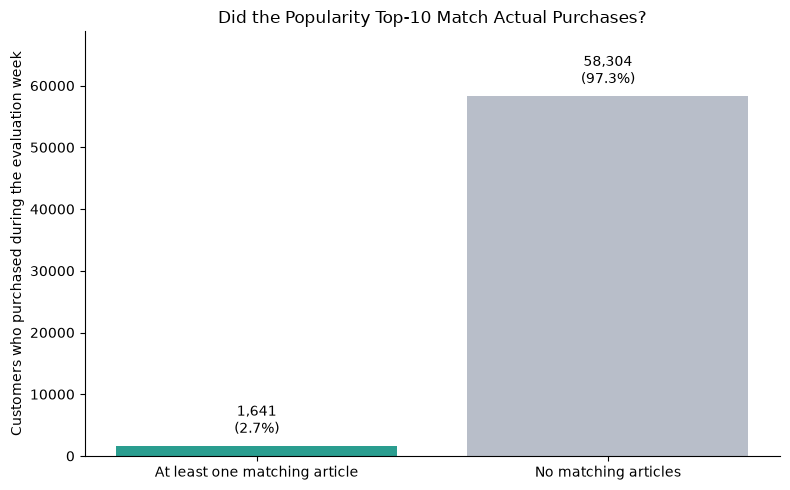

Of 59,945 purchasing customers, 1,641 purchased at least one recommended article.
Metrics saved: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\recommendations\recommendation_baseline_metrics.csv
Graph saved: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\reports\recommendations\popularity_baseline_hits.png


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Confirm that the recommendation list contains exactly top_k unique articles.
list_check = con.execute(f"""
    SELECT
        COUNT(*) AS recommendation_count,
        COUNT(DISTINCT article_id) AS unique_articles
    FROM recommendation_popularity_baseline
    WHERE recommendation_rank <= {int(top_k)}
""").df()

if not (
    list_check.loc[0, "recommendation_count"] == top_k
    and list_check.loc[0, "unique_articles"] == top_k
):
    raise ValueError("The baseline must contain top_k unique articles.")

# Match actual next-week purchases against the top-10 recommendations.
# No customer-by-catalog cross join is needed.
popularity_customer_metrics = con.execute(f"""
    WITH top_recommendations AS (
        SELECT article_id, recommendation_rank
        FROM recommendation_popularity_baseline
        WHERE recommendation_rank <= {int(top_k)}
    )
    SELECT
        actual.customer_id,
        COUNT(*) AS actual_articles,
        COUNT(rec.article_id) AS matching_articles,
        SUM(
            CASE
                WHEN rec.article_id IS NOT NULL
                THEN 1.0 / LOG2(rec.recommendation_rank + 1)
                ELSE 0.0
            END
        ) AS dcg
    FROM recommendation_test_purchases AS actual
    LEFT JOIN top_recommendations AS rec
        ON actual.article_id = rec.article_id
    GROUP BY actual.customer_id
""").df()

if popularity_customer_metrics.empty:
    raise ValueError("No next-week purchases are available for evaluation.")

# Ideal ranking score for customers with 1, 2, ..., top_k relevant articles.
ideal_dcg_lookup = np.concatenate([
    [0.0],
    np.cumsum(1.0 / np.log2(np.arange(1, top_k + 1) + 1))
])

ideal_match_count = np.minimum(
    popularity_customer_metrics["actual_articles"].to_numpy(dtype=int),
    top_k
)

popularity_customer_metrics["hit"] = (
    popularity_customer_metrics["matching_articles"] > 0
).astype(int)

popularity_customer_metrics["precision"] = (
    popularity_customer_metrics["matching_articles"] / top_k
)

popularity_customer_metrics["recall"] = (
    popularity_customer_metrics["matching_articles"]
    / popularity_customer_metrics["actual_articles"]
)

popularity_customer_metrics["ndcg"] = (
    popularity_customer_metrics["dcg"]
    / ideal_dcg_lookup[ideal_match_count]
)

# Each customer receives equal weight in these average metrics.
popularity_results = pd.DataFrame([{
    "model": "Recent popularity",
    "evaluated_customers": len(popularity_customer_metrics),
    "top_k": top_k,
    "hit_rate": popularity_customer_metrics["hit"].mean(),
    "precision": popularity_customer_metrics["precision"].mean(),
    "recall": popularity_customer_metrics["recall"].mean(),
    "ndcg": popularity_customer_metrics["ndcg"].mean(),
}])

display(
    popularity_results.style.format({
        "evaluated_customers": "{:,}",
        "hit_rate": "{:.2%}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "ndcg": "{:.4f}",
    })
)

# Simple graph: how many customers received at least one matching recommendation?
matched_customers = int(popularity_customer_metrics["hit"].sum())
evaluated_customers = len(popularity_customer_metrics)

counts = [
    matched_customers,
    evaluated_customers - matched_customers
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["At least one matching article", "No matching articles"],
    counts,
    color=["#2A9D8F", "#B8BEC9"]
)

for bar, count in zip(bars, counts):
    ax.annotate(
        f"{count:,}\n({count / evaluated_customers:.1%})",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_title(f"Did the Popularity Top-{top_k} Match Actual Purchases?")
ax.set_ylabel("Customers who purchased during the evaluation week")
ax.set_ylim(0, max(counts) * 1.18)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

figure_path = recommendation_report_dir / "popularity_baseline_hits.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

metrics_path = recommendation_report_dir / "recommendation_baseline_metrics.csv"
popularity_results.to_csv(metrics_path, index=False)

print(
    f"Of {evaluated_customers:,} purchasing customers, "
    f"{matched_customers:,} purchased at least one recommended article."
)
print("Metrics saved:", metrics_path)
print("Graph saved:", figure_path)

### Interpretation: Popularity Baseline

The recent-popularity baseline achieved a Hit Rate@10 of 2.74% and
Recall@10 of 1.03% among 59,945 existing customers who purchased during
the following week.

These results show limited coverage of individual purchasing preferences
when every customer receives the same 10 articles.

This baseline provides a reference for evaluating personalized methods.
The metrics describe observed purchase matches; they do not measure
customer satisfaction or additional sales caused by recommendations.

,evaluated_customers,customers_with_recent_preferences,customers_needing_fallback,profile_coverage_pct
0,59945,48396,11549,80.73


,product_group_name,customers
0,Garment Upper body,28064
1,Garment Lower body,8185
2,Garment Full body,4014
3,Underwear,2971
4,Accessories,2864
5,Socks & Tights,928
6,Nightwear,492
7,Shoes,433
8,Swimwear,401
9,Unknown,20


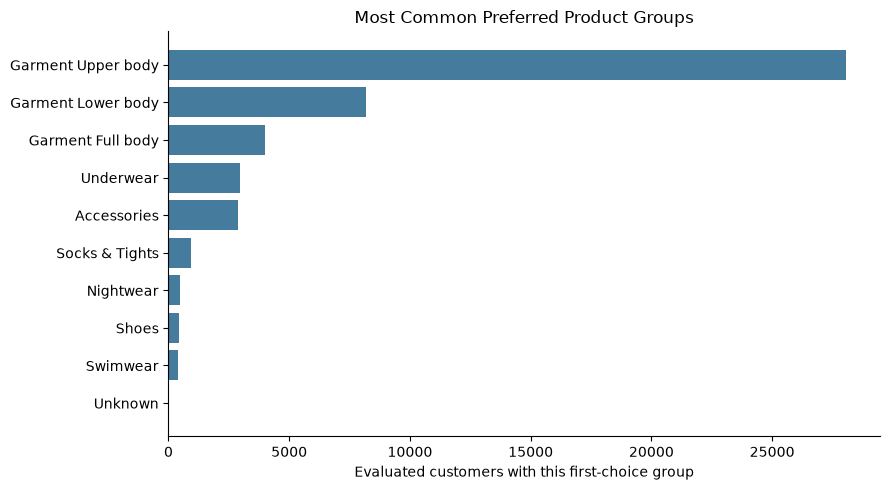

In [4]:
# Build customer preferences using only data available by the cutoff.
# This step creates profiles; it does not generate recommendations yet.

preference_window_days = 90

# A unique article key prevents joins from multiplying transaction rows.
article_key_check = con.execute("""
    SELECT
        COUNT(*) AS rows,
        COUNT(DISTINCT article_id) AS unique_articles,
        COUNT(*) FILTER (WHERE article_id IS NULL) AS missing_article_ids
    FROM articles
""").df()

if (
    article_key_check.loc[0, "rows"]
    != article_key_check.loc[0, "unique_articles"]
    or article_key_check.loc[0, "missing_article_ids"] != 0
):
    raise ValueError("articles must contain one row per nonmissing article_id.")

con.execute(f"""
    CREATE OR REPLACE TEMP TABLE recommendation_customer_preferences AS
    WITH group_activity AS (
        SELECT
            t.customer_id,
            a.product_group_name,
            COUNT(*) AS purchase_records,
            COUNT(DISTINCT t.t_dat) AS purchase_days,
            MAX(t.t_dat) AS latest_purchase_date
        FROM transactions AS t
        INNER JOIN articles AS a
            ON t.article_id = a.article_id
        WHERE t.t_dat > DATE '{recommendation_cutoff}'
                           - INTERVAL {preference_window_days} DAY
          AND t.t_dat <= DATE '{recommendation_cutoff}'
          AND a.product_group_name IS NOT NULL
        GROUP BY t.customer_id, a.product_group_name
    )
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY customer_id
            ORDER BY
                purchase_records DESC,
                purchase_days DESC,
                latest_purchase_date DESC,
                product_group_name
        ) AS preference_rank
    FROM group_activity
""")

# Profile coverage among the SAME customers used for baseline evaluation.
profile_coverage = con.execute("""
    WITH evaluation_customers AS (
        SELECT DISTINCT customer_id
        FROM recommendation_test_purchases
    ),
    profiled_customers AS (
        SELECT DISTINCT customer_id
        FROM recommendation_customer_preferences
    )
    SELECT
        COUNT(*) AS evaluated_customers,
        COUNT(p.customer_id) AS customers_with_recent_preferences,
        COUNT(*) - COUNT(p.customer_id) AS customers_needing_fallback,
        ROUND(
            100.0 * COUNT(p.customer_id) / COUNT(*), 2
        ) AS profile_coverage_pct
    FROM evaluation_customers AS e
    LEFT JOIN profiled_customers AS p
        ON e.customer_id = p.customer_id
""").df()

display(profile_coverage)

# Show the most common first-choice product groups in the evaluation cohort.
preferred_groups = con.execute("""
    SELECT
        p.product_group_name,
        COUNT(*) AS customers
    FROM recommendation_customer_preferences AS p
    INNER JOIN (
        SELECT DISTINCT customer_id
        FROM recommendation_test_purchases
    ) AS e
        ON p.customer_id = e.customer_id
    WHERE p.preference_rank = 1
    GROUP BY p.product_group_name
    ORDER BY customers DESC, p.product_group_name
""").df()

display(preferred_groups)

if not preferred_groups.empty:
    plot_data = preferred_groups.head(10).sort_values("customers")

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(
        plot_data["product_group_name"],
        plot_data["customers"],
        color="#457B9D"
    )
    ax.set_title("Most Common Preferred Product Groups")
    ax.set_xlabel("Evaluated customers with this first-choice group")
    ax.set_ylabel("")
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()

    fig.savefig(
        recommendation_report_dir / "customer_product_preferences.png",
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("No recent preferences found; check article joins and date coverage.")

## 3. Personalized Recommendations Using Product-Group Preferences

For each customer, recommend the most popular articles within their
highest-ranked product group.

- Customer preferences use the 90 days before the cutoff.
- Article popularity uses the 28 days before the cutoff.
- Global popular articles fill any remaining recommendation positions.
- Customers without recent preferences receive the global popularity list.
- Each customer receives 10 unique articles.
- Previously purchased articles remain eligible.

This is a rule-based personalized baseline. Customers with the same preferred
group may receive identical recommendations.

For efficient development, recommendations are generated for the same customers
used in baseline evaluation. Their future purchases do not influence item ranking.

In [5]:
# 1. Rank recently popular articles within each product group.
con.execute("""
    CREATE OR REPLACE TEMP TABLE recommendation_group_popularity AS
    SELECT
        p.article_id,
        a.product_group_name,
        p.purchase_records,
        p.recommendation_rank AS global_rank,
        ROW_NUMBER() OVER (
            PARTITION BY a.product_group_name
            ORDER BY p.purchase_records DESC, p.article_id
        ) AS group_rank
    FROM recommendation_popularity_baseline AS p
    INNER JOIN articles AS a
        ON p.article_id = a.article_id
    WHERE a.product_group_name IS NOT NULL
""")

# 2. Generate preferred-group candidates and global fallback candidates.
# Restrict to the evaluation cohort to keep this development step lightweight.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE category_recommendations AS
    WITH evaluation_customers AS (
        SELECT DISTINCT customer_id
        FROM recommendation_test_purchases
    ),
    preferred_candidates AS (
        SELECT
            e.customer_id,
            g.article_id,
            0 AS source_priority,
            g.group_rank AS source_rank,
            'Preferred product group' AS recommendation_source
        FROM evaluation_customers AS e
        INNER JOIN recommendation_customer_preferences AS p
            ON e.customer_id = p.customer_id
           AND p.preference_rank = 1
        INNER JOIN recommendation_group_popularity AS g
            ON p.product_group_name = g.product_group_name
        WHERE g.group_rank <= {int(top_k)}
    ),
    fallback_candidates AS (
        SELECT
            e.customer_id,
            g.article_id,
            1 AS source_priority,
            g.recommendation_rank AS source_rank,
            'Global popularity fallback' AS recommendation_source
        FROM evaluation_customers AS e
        CROSS JOIN (
            SELECT article_id, recommendation_rank
            FROM recommendation_popularity_baseline
            WHERE recommendation_rank <= {int(top_k)}
        ) AS g
    ),
    all_candidates AS (
        SELECT * FROM preferred_candidates
        UNION ALL
        SELECT * FROM fallback_candidates
    ),
    deduplicated AS (
        SELECT *
        FROM all_candidates
        QUALIFY ROW_NUMBER() OVER (
            PARTITION BY customer_id, article_id
            ORDER BY source_priority, source_rank
        ) = 1
    ),
    ranked AS (
        SELECT
            customer_id,
            article_id,
            recommendation_source,
            ROW_NUMBER() OVER (
                PARTITION BY customer_id
                ORDER BY source_priority, source_rank, article_id
            ) AS recommendation_rank
        FROM deduplicated
    )
    SELECT *
    FROM ranked
    WHERE recommendation_rank <= {int(top_k)}
""")

# 3. Verify that every evaluation customer has exactly 10 unique articles.
recommendation_check = con.execute(f"""
    WITH per_customer AS (
        SELECT
            customer_id,
            COUNT(*) AS recommendations,
            COUNT(DISTINCT article_id) AS unique_articles
        FROM category_recommendations
        GROUP BY customer_id
    )
    SELECT
        COUNT(*) AS customers,
        SUM(recommendations) AS recommendation_rows,
        MIN(recommendations) AS minimum_list_size,
        MAX(recommendations) AS maximum_list_size,
        COUNT(*) FILTER (
            WHERE recommendations != {int(top_k)}
               OR unique_articles != {int(top_k)}
        ) AS invalid_lists
    FROM per_customer
""").df()

display(recommendation_check)

expected_customers = con.execute("""
    SELECT COUNT(DISTINCT customer_id)
    FROM recommendation_test_purchases
""").fetchone()[0]

assert int(recommendation_check.loc[0, "customers"]) == expected_customers
assert int(recommendation_check.loc[0, "invalid_lists"]) == 0

# 4. Show how many recommendation positions came from each source.
recommendation_sources = con.execute("""
    SELECT
        recommendation_source,
        COUNT(*) AS recommendation_positions,
        COUNT(DISTINCT customer_id) AS customers_using_source
    FROM category_recommendations
    GROUP BY recommendation_source
    ORDER BY recommendation_positions DESC
""").df()

display(recommendation_sources)

print("Personalized recommendation lists are ready for evaluation.")

,customers,recommendation_rows,minimum_list_size,maximum_list_size,invalid_lists
0,59945,599450.0,10,10,0


,recommendation_source,recommendation_positions,customers_using_source
0,Preferred product group,483934,48396
1,Global popularity fallback,115516,11555


Personalized recommendation lists are ready for evaluation.


### Evaluating Product-Group Personalization

We compare personalized recommendations with the recent-popularity baseline
using the same customers, outcome window, recommendation count, and metrics.

Every evaluation customer is included, including those receiving fallback
recommendations. Customers with no matching recommendations receive zero scores.

An improvement indicates better prediction of observed purchases during this
development period; it does not establish additional sales caused by recommendations.

,model,evaluated_customers,top_k,hit_rate,precision,recall,ndcg
0,Recent popularity,"59,945",10,2.74%,0.29%,1.03%,0.0063
1,Preferred-group popularity,"59,945",10,3.50%,0.37%,1.33%,0.0087


Hit Rate@10 change: +0.76 percentage points


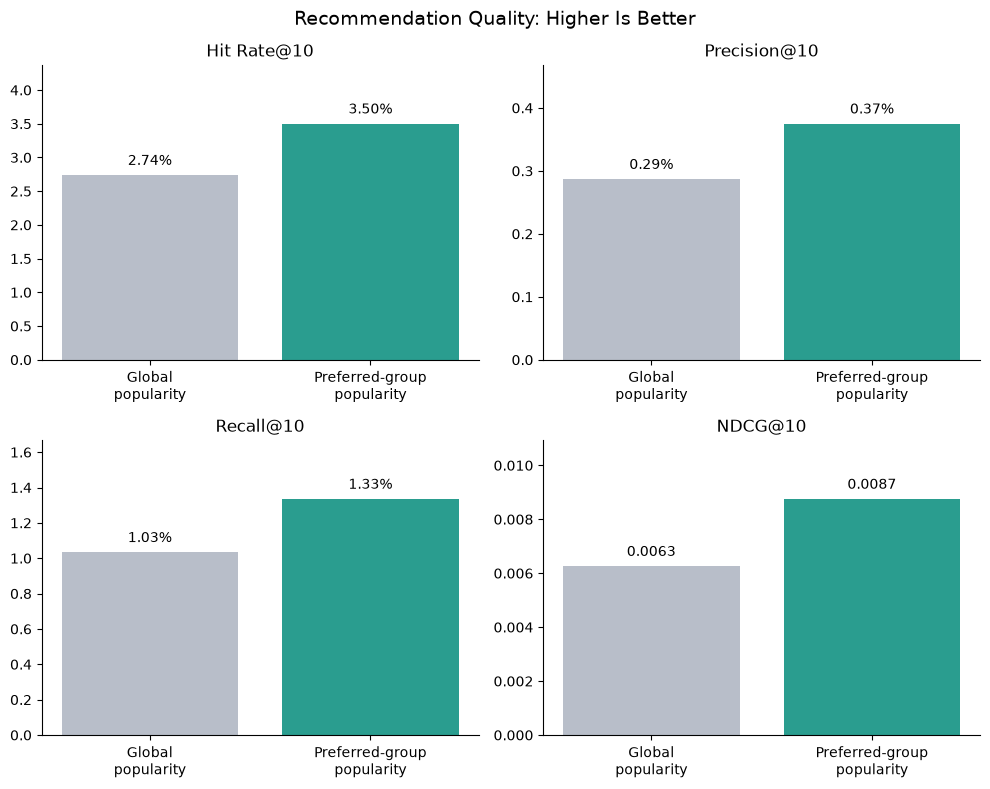

Comparison table and graph saved.


In [6]:
# Match each customer's actual purchases to their personalized recommendations.
category_customer_metrics = con.execute("""
    SELECT
        actual.customer_id,
        COUNT(*) AS actual_articles,
        COUNT(rec.article_id) AS matching_articles,
        SUM(
            CASE
                WHEN rec.article_id IS NOT NULL
                THEN 1.0 / LOG2(rec.recommendation_rank + 1)
                ELSE 0.0
            END
        ) AS dcg
    FROM recommendation_test_purchases AS actual
    LEFT JOIN category_recommendations AS rec
        ON actual.customer_id = rec.customer_id
       AND actual.article_id = rec.article_id
    GROUP BY actual.customer_id
""").df()

# Confirm both methods are evaluated on exactly the same customers.
assert set(category_customer_metrics["customer_id"]) == set(
    popularity_customer_metrics["customer_id"]
), "Evaluation customer populations do not match."

ideal_dcg_lookup = np.concatenate([
    [0.0],
    np.cumsum(1.0 / np.log2(np.arange(1, top_k + 1) + 1))
])

ideal_match_count = np.minimum(
    category_customer_metrics["actual_articles"].to_numpy(dtype=int),
    top_k
)

category_customer_metrics["hit"] = (
    category_customer_metrics["matching_articles"] > 0
).astype(int)

category_customer_metrics["precision"] = (
    category_customer_metrics["matching_articles"] / top_k
)

category_customer_metrics["recall"] = (
    category_customer_metrics["matching_articles"]
    / category_customer_metrics["actual_articles"]
)

category_customer_metrics["ndcg"] = (
    category_customer_metrics["dcg"]
    / ideal_dcg_lookup[ideal_match_count]
)

category_results = pd.DataFrame([{
    "model": "Preferred-group popularity",
    "evaluated_customers": len(category_customer_metrics),
    "top_k": top_k,
    "hit_rate": category_customer_metrics["hit"].mean(),
    "precision": category_customer_metrics["precision"].mean(),
    "recall": category_customer_metrics["recall"].mean(),
    "ndcg": category_customer_metrics["ndcg"].mean(),
}])

recommendation_comparison = pd.concat(
    [popularity_results, category_results],
    ignore_index=True
)

display(
    recommendation_comparison.style.format({
        "evaluated_customers": "{:,}",
        "hit_rate": "{:.2%}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "ndcg": "{:.4f}",
    })
)

# Show the hit-rate difference in percentage points.
baseline_hit_rate = float(popularity_results.iloc[0]["hit_rate"])
category_hit_rate = float(category_results.iloc[0]["hit_rate"])

print(
    "Hit Rate@10 change: "
    f"{100 * (category_hit_rate - baseline_hit_rate):+.2f} percentage points"
)

# Separate panels keep the different metric scales readable.
metric_specs = [
    ("hit_rate", "Hit Rate@10", 100, "%"),
    ("precision", "Precision@10", 100, "%"),
    ("recall", "Recall@10", 100, "%"),
    ("ndcg", "NDCG@10", 1, ""),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
labels = ["Global\npopularity", "Preferred-group\npopularity"]

for ax, (metric, title, scale, suffix) in zip(
    axes.flat, metric_specs
):
    values = recommendation_comparison[metric].to_numpy() * scale

    bars = ax.bar(
        labels,
        values,
        color=["#B8BEC9", "#2A9D8F"]
    )

    for bar, value in zip(bars, values):
        label = f"{value:.2f}{suffix}" if suffix else f"{value:.4f}"
        ax.annotate(
            label,
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom"
        )

    ax.set_title(title)
    ax.set_ylim(0, max(float(values.max()) * 1.25, 0.001))
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Recommendation Quality: Higher Is Better", fontsize=14)
fig.tight_layout()

fig.savefig(
    recommendation_report_dir / "popularity_vs_category_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

recommendation_comparison.to_csv(
    recommendation_report_dir / "popularity_vs_category_metrics.csv",
    index=False
)

print("Comparison table and graph saved.")

### Findings: Product-Group Personalization

Preferred-group recommendations improved all four evaluation metrics.
Hit Rate@10 increased from 2.74% to 3.50%, while Recall@10 increased
from 1.03% to 1.33%.

The results suggest that recent product-group preferences provide useful
information beyond global popularity. However, absolute purchase-match
rates remain low.

The method groups customers by a broad preference and does not learn
relationships between individual articles. We next investigate item-to-item
collaborative filtering.

## 4. Item-to-Item Collaborative Filtering

This method learns article relationships from overlapping customer purchase
histories.

We use purchases from the 90 days before the recommendation cutoff.
Each customer–article pair appears once in the interaction table.

Relationships are learned from all customers active in that historical window,
not only customers who purchased during the evaluation week.

Future purchases are excluded from training. Popularity recommendations
will provide a fallback when useful personalized candidates are unavailable.

In [8]:
collaborative_window_days = 90

# One row per historical customer–article pair.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE recommendation_cf_interactions AS
    SELECT
        customer_id,
        article_id,
        COUNT(*) AS purchase_records,
        MAX(t_dat) AS last_purchase_date
    FROM transactions
    WHERE t_dat > DATE '{recommendation_cutoff}'
                       - INTERVAL {collaborative_window_days} DAY
      AND t_dat <= DATE '{recommendation_cutoff}'
      AND customer_id IS NOT NULL
      AND article_id IS NOT NULL
    GROUP BY customer_id, article_id
""")

# Size of the interaction data.
interaction_summary = con.execute("""
    SELECT
        COUNT(*) AS customer_article_pairs,
        COUNT(DISTINCT customer_id) AS historical_customers,
        COUNT(DISTINCT article_id) AS historical_articles,
        MIN(last_purchase_date) AS earliest_pair_last_purchase,
        MAX(last_purchase_date) AS latest_purchase
    FROM recommendation_cf_interactions
""").df()

display(interaction_summary)

# Customer history size affects the cost of article-pair calculations.
history_size_summary = con.execute("""
    WITH customer_sizes AS (
        SELECT
            customer_id,
            COUNT(*) AS distinct_articles
        FROM recommendation_cf_interactions
        GROUP BY customer_id
    )
    SELECT
        MIN(distinct_articles) AS minimum_articles,
        MEDIAN(distinct_articles) AS median_articles,
        ROUND(AVG(distinct_articles), 2) AS mean_articles,
        QUANTILE_CONT(distinct_articles, 0.95) AS p95_articles,
        MAX(distinct_articles) AS maximum_articles,
        SUM(
            distinct_articles::DOUBLE * (distinct_articles - 1) / 2
        ) AS possible_unordered_pair_contributions
    FROM customer_sizes
""").df()

display(history_size_summary)

# How many evaluation customers have usable recent history?
cf_coverage = con.execute("""
    WITH evaluation_customers AS (
        SELECT DISTINCT customer_id
        FROM recommendation_test_purchases
    ),
    historical_customers AS (
        SELECT DISTINCT customer_id
        FROM recommendation_cf_interactions
    )
    SELECT
        COUNT(*) AS evaluated_customers,
        COUNT(h.customer_id) AS customers_with_recent_history,
        COUNT(*) - COUNT(h.customer_id) AS customers_without_recent_history,
        ROUND(
            100.0 * COUNT(h.customer_id) / COUNT(*), 2
        ) AS history_coverage_pct
    FROM evaluation_customers AS e
    LEFT JOIN historical_customers AS h
        ON e.customer_id = h.customer_id
""").df()

display(cf_coverage)

print("Historical interactions are ready. No article pairs computed yet.")

,customer_article_pairs,historical_customers,historical_articles,earliest_pair_last_purchase,latest_purchase
0,2933612,515461,39900,2019-10-03,2019-12-31


,minimum_articles,median_articles,mean_articles,p95_articles,maximum_articles,possible_unordered_pair_contributions
0,1,4.0,5.69,17.0,330,17157993.0


,evaluated_customers,customers_with_recent_history,customers_without_recent_history,history_coverage_pct
0,59945,48396,11549,80.73


Historical interactions are ready. No article pairs computed yet.


### Learning Article Similarities

We represent each article by the customers who purchased it during the
historical 90-day window.

Binary cosine similarity is calculated as:

similarity(A, B) = shared customers / sqrt(customers_A × customers_B)

We apply two development settings:
- Require at least 3 shared customers.
- Multiply similarity by shared_customers / (shared_customers + 10)
  to reduce the influence of relationships with limited evidence.

For each article, retain its 20 highest-scoring neighbors.
Self-matches are excluded.

These relationships describe shared purchase histories, not necessarily
products purchased in the same basket or products with similar appearance.
All calculations use purchases on or before the cutoff.

In [9]:
import time

minimum_shared_customers = 3
similarity_shrinkage = 10.0
neighbors_per_article = 20

started = time.perf_counter()

# 1. Count unique customers per article.
# The interaction table already contains unique customer–article pairs.
con.execute("""
    CREATE OR REPLACE TEMP TABLE recommendation_cf_article_support AS
    SELECT
        article_id,
        COUNT(*) AS customer_count
    FROM recommendation_cf_interactions
    GROUP BY article_id
""")

# 2. Count customers shared by each unordered pair of different articles.
# The '<' condition avoids self-pairs and avoids counting both A-B and B-A.
print("Counting shared customers between articles...")

con.execute(f"""
    CREATE OR REPLACE TEMP TABLE recommendation_cf_pair_counts AS
    SELECT
        a.article_id AS article_a,
        b.article_id AS article_b,
        COUNT(*) AS shared_customers
    FROM recommendation_cf_interactions AS a
    INNER JOIN recommendation_cf_interactions AS b
        ON a.customer_id = b.customer_id
       AND a.article_id < b.article_id
    GROUP BY a.article_id, b.article_id
    HAVING COUNT(*) >= {int(minimum_shared_customers)}
""")

# 3. Calculate cosine similarity and shrinkage-adjusted similarity.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE recommendation_cf_pair_scores AS
    SELECT
        p.article_a,
        p.article_b,
        p.shared_customers,
        p.shared_customers::DOUBLE
            / SQRT(
                a.customer_count::DOUBLE * b.customer_count::DOUBLE
            ) AS cosine_similarity,
        (
            p.shared_customers::DOUBLE
            / SQRT(
                a.customer_count::DOUBLE * b.customer_count::DOUBLE
            )
        ) * (
            p.shared_customers::DOUBLE
            / (p.shared_customers + {float(similarity_shrinkage)})
        ) AS similarity_score
    FROM recommendation_cf_pair_counts AS p
    INNER JOIN recommendation_cf_article_support AS a
        ON p.article_a = a.article_id
    INNER JOIN recommendation_cf_article_support AS b
        ON p.article_b = b.article_id
""")

# 4. Make relationships available in both directions, then retain top neighbors.
print("Selecting the strongest neighbors for each article...")

con.execute(f"""
    CREATE OR REPLACE TEMP TABLE recommendation_item_neighbors AS
    WITH directed_pairs AS (
        SELECT
            article_a AS source_article_id,
            article_b AS neighbor_article_id,
            shared_customers,
            cosine_similarity,
            similarity_score
        FROM recommendation_cf_pair_scores

        UNION ALL

        SELECT
            article_b AS source_article_id,
            article_a AS neighbor_article_id,
            shared_customers,
            cosine_similarity,
            similarity_score
        FROM recommendation_cf_pair_scores
    ),
    ranked AS (
        SELECT
            *,
            ROW_NUMBER() OVER (
                PARTITION BY source_article_id
                ORDER BY
                    similarity_score DESC,
                    shared_customers DESC,
                    neighbor_article_id
            ) AS neighbor_rank
        FROM directed_pairs
    )
    SELECT *
    FROM ranked
    WHERE neighbor_rank <= {int(neighbors_per_article)}
""")

# 5. Summarize the learned neighbor table.
neighbor_summary = con.execute("""
    SELECT
        COUNT(*) AS directed_neighbor_links,
        COUNT(DISTINCT source_article_id) AS articles_with_neighbors,
        MIN(shared_customers) AS minimum_shared_customers,
        ROUND(AVG(similarity_score), 4) AS mean_similarity,
        ROUND(MAX(similarity_score), 4) AS maximum_similarity
    FROM recommendation_item_neighbors
""").df()

display(neighbor_summary)

if int(neighbor_summary.loc[0, "directed_neighbor_links"]) == 0:
    raise ValueError("No article relationships passed the support threshold.")

# 6. Inspect neighbors of one example article.
# Choose the most globally popular article that has learned neighbors.
example_neighbors = con.execute("""
    WITH example_article AS (
        SELECT p.article_id
        FROM recommendation_popularity_baseline AS p
        WHERE EXISTS (
            SELECT 1
            FROM recommendation_item_neighbors AS n
            WHERE n.source_article_id = p.article_id
        )
        ORDER BY p.recommendation_rank
        LIMIT 1
    )
    SELECT
        n.source_article_id,
        source.prod_name AS source_product,
        n.neighbor_rank,
        n.neighbor_article_id,
        neighbor.prod_name AS recommended_product,
        n.shared_customers,
        ROUND(n.cosine_similarity, 4) AS cosine_similarity,
        ROUND(n.similarity_score, 4) AS adjusted_similarity
    FROM recommendation_item_neighbors AS n
    INNER JOIN example_article AS e
        ON n.source_article_id = e.article_id
    LEFT JOIN articles AS source
        ON n.source_article_id = source.article_id
    LEFT JOIN articles AS neighbor
        ON n.neighbor_article_id = neighbor.article_id
    WHERE n.neighbor_rank <= 10
    ORDER BY n.neighbor_rank
""").df()

display(example_neighbors)

print(f"Completed in {time.perf_counter() - started:,.1f} seconds.")

Counting shared customers between articles...
Selecting the strongest neighbors for each article...


,directed_neighbor_links,articles_with_neighbors,minimum_shared_customers,mean_similarity,maximum_similarity
0,204734,17456,3,0.0181,0.8761


,source_article_id,source_product,neighbor_rank,neighbor_article_id,recommended_product,shared_customers,cosine_similarity,adjusted_similarity
0,0819139001,H2 Lauren dress PI,1,0827698001,Metro,61,0.0374,0.0321
1,0819139001,H2 Lauren dress PI,2,0733098022,Minja top,60,0.0347,0.0297
2,0819139001,H2 Lauren dress PI,3,0826492005,Dame,45,0.0321,0.0262
3,0819139001,H2 Lauren dress PI,4,0796210010,Enter(1),50,0.0279,0.0232
4,0819139001,H2 Lauren dress PI,5,0826498003,Fletcher,36,0.0275,0.0215
5,0819139001,H2 Lauren dress PI,6,0819147001,H2 Canna top PI,52,0.0254,0.0213
6,0819139001,H2 Lauren dress PI,7,0819143001,H2 Aster dress PI,49,0.0256,0.0213
7,0819139001,H2 Lauren dress PI,8,0826498002,Fletcher,43,0.0258,0.0209
8,0819139001,H2 Lauren dress PI,9,0820873001,Kat dress,52,0.0241,0.0202
9,0819139001,H2 Lauren dress PI,10,0830538001,Folly,26,0.0260,0.0188


Completed in 10.8 seconds.


What this produces: a lookup table of up to 20 related articles for each supported article. The similarity score is not a purchase probability.
Share the summary and example table next. Then we’ll combine these neighbors with each customer’s purchase history to generate their top 10 recommendations.

### Generating Item-to-Item Recommendations

For each customer:

1. Retrieve the articles they purchased during the historical 90-day window.
2. Retrieve the learned neighbors of those articles.
3. Sum similarity scores when multiple historical articles support the same candidate.
4. Rank candidates by their total score.
5. Fill remaining positions with global popular articles.

Each customer receives 10 unique recommendations. Previously purchased articles
remain eligible, although an article cannot recommend itself through a self-link.

Customers without usable article relationships receive popularity fallback.
Scores represent relative recommendation strength, not purchase probabilities.

Scoring personalized article candidates...


,customers,recommendation_rows,minimum_list_size,maximum_list_size,invalid_lists,customers_with_personalized_recommendations,customers_with_only_fallback
0,59945,599450.0,10,10,0,48119,11826


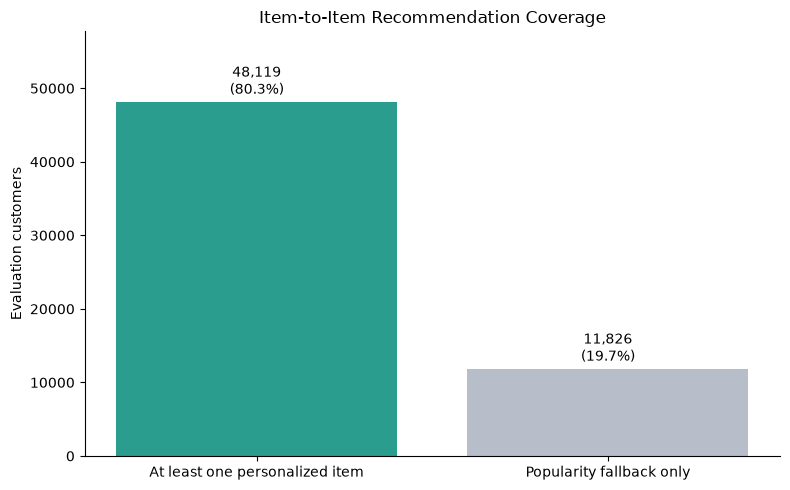

Item-to-item recommendation lists are ready for evaluation.


In [10]:
# 1. Score candidate articles using each customer's historical purchases.
print("Scoring personalized article candidates...")

con.execute("""
    CREATE OR REPLACE TEMP TABLE recommendation_cf_candidate_scores AS
    WITH evaluation_customers AS (
        SELECT DISTINCT customer_id
        FROM recommendation_test_purchases
    )
    SELECT
        h.customer_id,
        n.neighbor_article_id AS article_id,
        SUM(n.similarity_score) AS recommendation_score,
        COUNT(*) AS supporting_history_articles
    FROM recommendation_cf_interactions AS h
    INNER JOIN evaluation_customers AS e
        ON h.customer_id = e.customer_id
    INNER JOIN recommendation_item_neighbors AS n
        ON h.article_id = n.source_article_id
    GROUP BY h.customer_id, n.neighbor_article_id
""")

# 2. Keep the best personalized candidates.
# Article ID provides a reproducible tie-break.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE recommendation_cf_top_candidates AS
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY customer_id
            ORDER BY recommendation_score DESC, article_id
        ) AS candidate_rank
    FROM recommendation_cf_candidate_scores
    QUALIFY candidate_rank <= {int(top_k)}
""")

# 3. Add global fallback, remove duplicate articles, and finalize top-10 lists.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE item_cf_recommendations AS
    WITH evaluation_customers AS (
        SELECT DISTINCT customer_id
        FROM recommendation_test_purchases
    ),
    candidates AS (
        SELECT
            customer_id,
            article_id,
            recommendation_score,
            0 AS source_priority,
            candidate_rank AS source_rank,
            'Item-to-item similarity' AS recommendation_source
        FROM recommendation_cf_top_candidates

        UNION ALL

        SELECT
            e.customer_id,
            p.article_id,
            0.0 AS recommendation_score,
            1 AS source_priority,
            p.recommendation_rank AS source_rank,
            'Global popularity fallback' AS recommendation_source
        FROM evaluation_customers AS e
        CROSS JOIN (
            SELECT article_id, recommendation_rank
            FROM recommendation_popularity_baseline
            WHERE recommendation_rank <= {int(top_k)}
        ) AS p
    ),
    deduplicated AS (
        SELECT *
        FROM candidates
        QUALIFY ROW_NUMBER() OVER (
            PARTITION BY customer_id, article_id
            ORDER BY source_priority, source_rank
        ) = 1
    ),
    ranked AS (
        SELECT
            customer_id,
            article_id,
            recommendation_score,
            recommendation_source,
            ROW_NUMBER() OVER (
                PARTITION BY customer_id
                ORDER BY source_priority, source_rank, article_id
            ) AS recommendation_rank
        FROM deduplicated
    )
    SELECT *
    FROM ranked
    WHERE recommendation_rank <= {int(top_k)}
""")

# 4. Validate list lengths and unique articles.
cf_list_check = con.execute(f"""
    WITH customer_lists AS (
        SELECT
            customer_id,
            COUNT(*) AS list_size,
            COUNT(DISTINCT article_id) AS unique_articles,
            COUNT(*) FILTER (
                WHERE recommendation_source = 'Item-to-item similarity'
            ) AS personalized_positions
        FROM item_cf_recommendations
        GROUP BY customer_id
    )
    SELECT
        COUNT(*) AS customers,
        SUM(list_size) AS recommendation_rows,
        MIN(list_size) AS minimum_list_size,
        MAX(list_size) AS maximum_list_size,
        COUNT(*) FILTER (
            WHERE list_size != {int(top_k)}
               OR unique_articles != {int(top_k)}
        ) AS invalid_lists,
        COUNT(*) FILTER (
            WHERE personalized_positions > 0
        ) AS customers_with_personalized_recommendations,
        COUNT(*) FILTER (
            WHERE personalized_positions = 0
        ) AS customers_with_only_fallback
    FROM customer_lists
""").df()

display(cf_list_check)

expected_customers = con.execute("""
    SELECT COUNT(DISTINCT customer_id)
    FROM recommendation_test_purchases
""").fetchone()[0]

assert int(cf_list_check.loc[0, "customers"]) == expected_customers
assert int(cf_list_check.loc[0, "invalid_lists"]) == 0

# 5. Visualize actual personalization coverage.
counts = [
    int(cf_list_check.loc[0, "customers_with_personalized_recommendations"]),
    int(cf_list_check.loc[0, "customers_with_only_fallback"])
]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    ["At least one personalized item", "Popularity fallback only"],
    counts,
    color=["#2A9D8F", "#B8BEC9"]
)

for bar, count in zip(bars, counts):
    ax.annotate(
        f"{count:,}\n({count / expected_customers:.1%})",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Item-to-Item Recommendation Coverage")
ax.set_ylabel("Evaluation customers")
ax.set_ylim(0, max(counts) * 1.2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(
    recommendation_report_dir / "item_cf_personalization_coverage.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

print("Item-to-item recommendation lists are ready for evaluation.")

### Evaluating Item-to-Item Collaborative Filtering

We evaluate item-to-item recommendations against the same next-week purchases
used for both previous baselines.

All 59,945 evaluation customers remain included, including customers receiving
only popularity fallback. Each customer receives equal weight in the metrics.

The comparison measures Hit Rate@10, Precision@10, Recall@10, and NDCG@10.
Higher values indicate better agreement with observed purchases.

,model,evaluated_customers,top_k,hit_rate,precision,recall,ndcg
0,Recent popularity,"59,945",10,2.74%,0.29%,1.03%,0.0063
1,Preferred-group popularity,"59,945",10,3.50%,0.37%,1.33%,0.0087
2,Item-to-item collaborative filtering,"59,945",10,5.65%,0.66%,2.65%,0.0173


Item-to-item vs Recent popularity: +2.91 percentage points in Hit Rate@10
Item-to-item vs Preferred-group popularity: +2.15 percentage points in Hit Rate@10


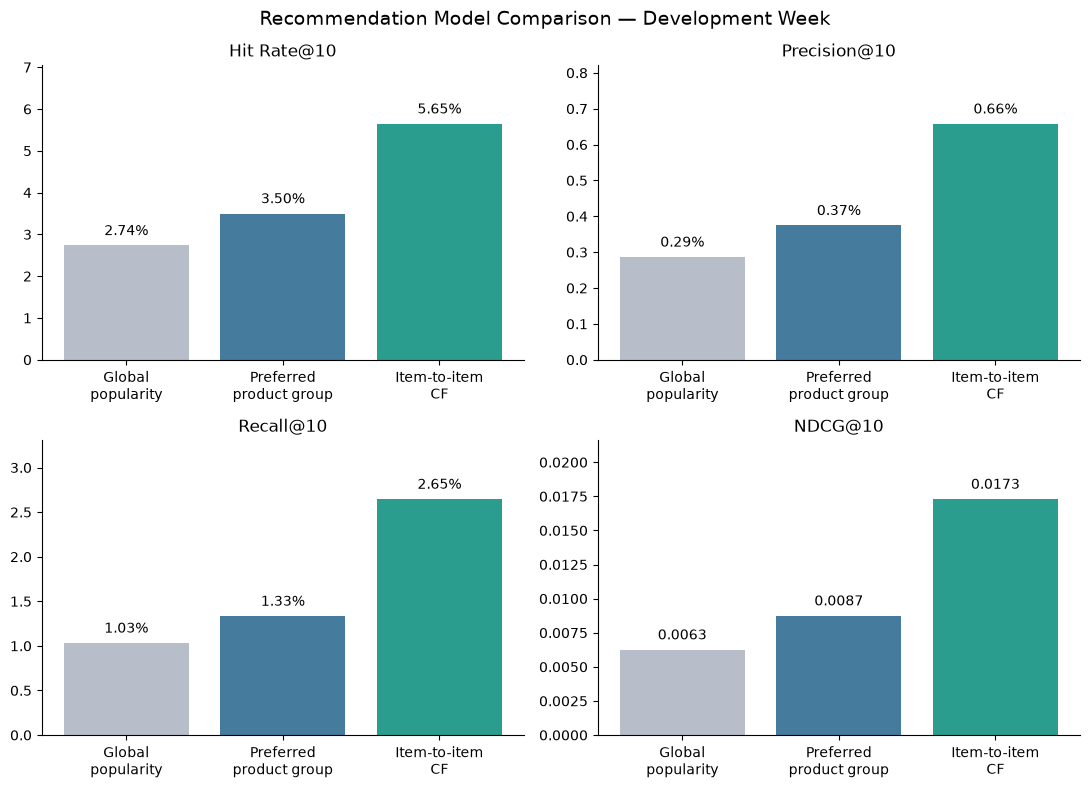

Comparison table and graph saved.


In [11]:
# 1. Match actual purchases to each customer's item-to-item recommendations.
item_cf_customer_metrics = con.execute("""
    SELECT
        actual.customer_id,
        COUNT(*) AS actual_articles,
        COUNT(rec.article_id) AS matching_articles,
        SUM(
            CASE
                WHEN rec.article_id IS NOT NULL
                THEN 1.0 / LOG2(rec.recommendation_rank + 1)
                ELSE 0.0
            END
        ) AS dcg
    FROM recommendation_test_purchases AS actual
    LEFT JOIN item_cf_recommendations AS rec
        ON actual.customer_id = rec.customer_id
       AND actual.article_id = rec.article_id
    GROUP BY actual.customer_id
""").df()

assert set(item_cf_customer_metrics["customer_id"]) == set(
    popularity_customer_metrics["customer_id"]
), "Evaluation customer populations do not match."

# 2. Calculate the same customer-level metrics as the previous methods.
ideal_dcg_lookup = np.concatenate([
    [0.0],
    np.cumsum(1.0 / np.log2(np.arange(1, top_k + 1) + 1))
])

ideal_match_count = np.minimum(
    item_cf_customer_metrics["actual_articles"].to_numpy(dtype=int),
    top_k
)

item_cf_customer_metrics["hit"] = (
    item_cf_customer_metrics["matching_articles"] > 0
).astype(int)

item_cf_customer_metrics["precision"] = (
    item_cf_customer_metrics["matching_articles"] / top_k
)

item_cf_customer_metrics["recall"] = (
    item_cf_customer_metrics["matching_articles"]
    / item_cf_customer_metrics["actual_articles"]
)

item_cf_customer_metrics["ndcg"] = (
    item_cf_customer_metrics["dcg"]
    / ideal_dcg_lookup[ideal_match_count]
)

item_cf_results = pd.DataFrame([{
    "model": "Item-to-item collaborative filtering",
    "evaluated_customers": len(item_cf_customer_metrics),
    "top_k": top_k,
    "hit_rate": item_cf_customer_metrics["hit"].mean(),
    "precision": item_cf_customer_metrics["precision"].mean(),
    "recall": item_cf_customer_metrics["recall"].mean(),
    "ndcg": item_cf_customer_metrics["ndcg"].mean(),
}])

# 3. Compare all three methods without duplicating rows on reruns.
recommendation_comparison = pd.concat(
    [popularity_results, category_results, item_cf_results],
    ignore_index=True
)

display(
    recommendation_comparison.style.format({
        "evaluated_customers": "{:,}",
        "hit_rate": "{:.2%}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "ndcg": "{:.4f}",
    })
)

# 4. Explain the hit-rate differences in percentage points.
cf_hit_rate = float(item_cf_results.iloc[0]["hit_rate"])

for previous_result in [popularity_results, category_results]:
    previous = previous_result.iloc[0]
    difference_pp = 100 * (cf_hit_rate - float(previous["hit_rate"]))
    print(
        f"Item-to-item vs {previous['model']}: "
        f"{difference_pp:+.2f} percentage points in Hit Rate@{top_k}"
    )

# 5. Plot all four metrics separately.
metric_specs = [
    ("hit_rate", f"Hit Rate@{top_k}", 100, "%"),
    ("precision", f"Precision@{top_k}", 100, "%"),
    ("recall", f"Recall@{top_k}", 100, "%"),
    ("ndcg", f"NDCG@{top_k}", 1, ""),
]

labels = ["Global\npopularity", "Preferred\nproduct group", "Item-to-item\nCF"]
colors = ["#B8BEC9", "#457B9D", "#2A9D8F"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (metric, title, scale, suffix) in zip(axes.flat, metric_specs):
    values = recommendation_comparison[metric].to_numpy() * scale
    bars = ax.bar(labels, values, color=colors)

    for bar, value in zip(bars, values):
        label = f"{value:.2f}{suffix}" if suffix else f"{value:.4f}"
        ax.annotate(
            label,
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom"
        )

    ax.set_title(title)
    ax.set_ylim(0, max(float(values.max()) * 1.25, 0.001))
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Recommendation Model Comparison — Development Week", fontsize=14)
fig.tight_layout()

fig.savefig(
    recommendation_report_dir / "three_model_recommendation_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

recommendation_comparison.to_csv(
    recommendation_report_dir / "three_model_recommendation_metrics.csv",
    index=False
)

print("Comparison table and graph saved.")

### Findings: Item-to-Item Collaborative Filtering

Item-to-item collaborative filtering achieved the strongest development-period
results among the three methods evaluated.

Hit Rate@10 increased from 2.74% for global popularity to 5.65%.
Recall@10 increased from 1.03% to 2.65%, and NDCG@10 increased from
0.0063 to 0.0173.

These results suggest that relationships between individual articles provide
more useful personalization than the preferred-product-group rule in this
evaluation period.

Absolute purchase coverage remains limited. These findings apply to existing
customers who purchased during the development week and require confirmation
in a separate later evaluation period.

In [12]:
import sys
from importlib import util, metadata

print("Notebook Python:", sys.executable)

for package in ["numpy", "scipy", "implicit"]:
    if util.find_spec(package) is None:
        print(f"{package}: NOT INSTALLED")
    else:
        try:
            print(f"{package}: {metadata.version(package)}")
        except metadata.PackageNotFoundError:
            print(f"{package}: importable, version unavailable")

Notebook Python: c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\.venv\Scripts\python.exe
numpy: 2.5.4
scipy: 1.18.1
implicit: NOT INSTALLED


In [13]:
%pip install --only-binary=:all: implicit==0.7.3

   ---------------------------------------- 0.0/692.7 kB ? eta -:--:--
   ---------------------------------------- 692.7/692.7 kB 5.1 MB/s  0:00:00

   ---------------------------------------- 0/2 [tqdm]
   ---------------------------------------- 0/2 [tqdm]
   ---------------------------------------- 0/2 [tqdm]
   ---------------------------------------- 0/2 [tqdm]
   ---------------------------------------- 0/2 [tqdm]
   ---------------------------------------- 0/2 [tqdm]
   ---------------------------------------- 0/2 [tqdm]
   -------------------- ------------------- 1/2 [implicit]
   -------------------- ------------------- 1/2 [implicit]
   -------------------- ------------------- 1/2 [implicit]
   -------------------- ------------------- 1/2 [implicit]
   ---------------------------------------- 2/2 [implicit]

Note: you may need to restart the kernel to use updated packages.


In [14]:
import implicit
from implicit.als import AlternatingLeastSquares
from scipy.sparse import csr_matrix

print("implicit version:", implicit.__version__)
print("ALS and sparse matrix imports successful.")

c:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


implicit version: 0.7.3
ALS and sparse matrix imports successful.


## 5. Implicit ALS: Preparing the Interaction Matrix

Implicit ALS learns customer and article representations from purchase behavior.

The training matrix contains:
- Rows: customers active during the historical 90-day window.
- Columns: articles purchased during that window.
- Stored entries: confidence weights for observed customer–article purchases.

For observed purchases, confidence is defined as:

confidence = 1 + 10 × log(1 + purchase_records)

Repeated purchases increase confidence, while the logarithm limits their influence.
These weights are not ratings or purchase probabilities.

Unobserved entries represent unknown preferences, not confirmed dislikes.
The ALS objective treats them as zero-preference observations with lower confidence.

The matrix uses sparse storage, so we do not allocate every possible
customer–article combination. All training interactions precede the cutoff.

In [15]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

als_confidence_scale = 10.0

# 1. Create stable mappings from original IDs to consecutive integers.
# Keep original IDs intact, including leading zeros in article IDs.
con.execute("""
    CREATE OR REPLACE TEMP TABLE recommendation_als_user_map AS
    SELECT
        customer_id,
        (ROW_NUMBER() OVER (ORDER BY customer_id) - 1)::INTEGER
            AS user_index
    FROM (
        SELECT DISTINCT customer_id
        FROM recommendation_cf_interactions
    )
""")

con.execute("""
    CREATE OR REPLACE TEMP TABLE recommendation_als_item_map AS
    SELECT
        article_id,
        (ROW_NUMBER() OVER (ORDER BY article_id) - 1)::INTEGER
            AS item_index
    FROM (
        SELECT DISTINCT article_id
        FROM recommendation_cf_interactions
    )
""")

als_user_map = con.execute("""
    SELECT *
    FROM recommendation_als_user_map
    ORDER BY user_index
""").df()

als_item_map = con.execute("""
    SELECT *
    FROM recommendation_als_item_map
    ORDER BY item_index
""").df()

# 2. Retrieve numeric coordinates only, reducing repeated string storage.
als_coordinates = con.execute("""
    SELECT
        u.user_index,
        i.item_index,
        h.purchase_records
    FROM recommendation_cf_interactions AS h
    INNER JOIN recommendation_als_user_map AS u
        ON h.customer_id = u.customer_id
    INNER JOIN recommendation_als_item_map AS i
        ON h.article_id = i.article_id
""").df()

confidence_values = (
    1.0
    + als_confidence_scale
    * np.log1p(
        als_coordinates["purchase_records"].to_numpy(dtype=np.float32)
    )
).astype(np.float32)

# 3. Build a customer-by-article CSR matrix.
als_user_items = csr_matrix(
    (
        confidence_values,
        (
            als_coordinates["user_index"].to_numpy(dtype=np.int32),
            als_coordinates["item_index"].to_numpy(dtype=np.int32),
        ),
    ),
    shape=(len(als_user_map), len(als_item_map)),
    dtype=np.float32
)

als_user_items.sort_indices()

# 4. Validate the matrix.
assert als_user_items.nnz == len(als_coordinates)
assert np.isfinite(als_user_items.data).all()
assert (als_user_items.data > 0).all()

n_users, n_items = als_user_items.shape
possible_entries = int(n_users) * int(n_items)

sparse_bytes = (
    als_user_items.data.nbytes
    + als_user_items.indices.nbytes
    + als_user_items.indptr.nbytes
)

matrix_summary = pd.DataFrame([{
    "customers": n_users,
    "articles": n_items,
    "observed_customer_article_pairs": als_user_items.nnz,
    "density_pct": 100 * als_user_items.nnz / possible_entries,
    "sparse_matrix_MiB": sparse_bytes / (1024 ** 2),
    "equivalent_dense_float32_GiB": (
        possible_entries * np.dtype(np.float32).itemsize / (1024 ** 3)
    ),
    "minimum_confidence": float(als_user_items.data.min()),
    "maximum_confidence": float(als_user_items.data.max()),
}])

display(matrix_summary.round(4))

# Release intermediate arrays; retain the matrix and ID mappings.
del als_coordinates, confidence_values

print("ALS matrix ready:", als_user_items.shape)
print("Rows = customers; columns = articles.")
print("The model has not been trained yet.")

,customers,articles,observed_customer_article_pairs,density_pct,sparse_matrix_MiB,equivalent_dense_float32_GiB,minimum_confidence,maximum_confidence
0,515461,39900,2933612,0.0143,24.348,76.6177,7.9315,48.9579


ALS matrix ready: (515461, 39900)
Rows = customers; columns = articles.
The model has not been trained yet.


### Training the Implicit ALS Model

ALS learns a vector of 32 numerical factors for each customer and article.
These factors capture patterns in historical purchases; they do not have
predefined meanings such as age, category, or price preference.

The model alternates between updating customer factors and article factors.

Initial configuration:
- Factors: 32
- Training iterations: 20
- Regularization: 0.1
- Additional confidence multiplier (alpha): 1.0
- CPU threads: 2
- Random seed: 42

Regularization discourages excessively large factor values.
These are initial development settings, not proven optimal settings.

Training uses historical interactions only. Recommendation quality will
be measured separately against next-week purchases.

In [16]:
import time
import numpy as np
import pandas as pd

from implicit.cpu.als import AlternatingLeastSquares
from threadpoolctl import threadpool_limits

als_parameters = {
    "factors": 32,
    "regularization": 0.1,
    "alpha": 1.0,  # Confidence weights are already in als_user_items.
    "iterations": 20,
    "num_threads": 2,
    "random_state": 42,
}

print("Training ALS on historical purchases...")
print("Matrix shape:", als_user_items.shape)
print("Observed interactions:", f"{als_user_items.nnz:,}")

started = time.perf_counter()

# Limit BLAS threads to avoid competing with ALS's own CPU threads.
with threadpool_limits(limits=1, user_api="blas"):
    als_model = AlternatingLeastSquares(
        **als_parameters,
        dtype=np.float32,
        calculate_training_loss=False
    )

    als_model.fit(
        als_user_items,
        show_progress=True
    )

als_training_seconds = time.perf_counter() - started

# Verify that learned representations match our ID mappings.
assert als_model.user_factors.shape == (
    len(als_user_map), als_parameters["factors"]
)
assert als_model.item_factors.shape == (
    len(als_item_map), als_parameters["factors"]
)
assert np.isfinite(als_model.user_factors).all()
assert np.isfinite(als_model.item_factors).all()

factor_memory_mib = (
    als_model.user_factors.nbytes
    + als_model.item_factors.nbytes
) / (1024 ** 2)

als_training_summary = pd.DataFrame([{
    "model": "Implicit ALS",
    "training_customers": als_model.user_factors.shape[0],
    "training_articles": als_model.item_factors.shape[0],
    "factors": als_parameters["factors"],
    "iterations": als_parameters["iterations"],
    "regularization": als_parameters["regularization"],
    "training_seconds": als_training_seconds,
    "factor_arrays_MiB": factor_memory_mib,
    "all_factors_finite": True,
}])

display(als_training_summary.round(3))

als_training_summary.to_csv(
    recommendation_report_dir / "als_training_summary.csv",
    index=False
)

print("ALS training completed.")
print("Next: generate top-10 recommendations and evaluate purchase matches.")

Training ALS on historical purchases...
Matrix shape: (515461, 39900)
Observed interactions: 2,933,612


100%|██████████| 20/20 [00:23<00:00,  1.18s/it]


,model,training_customers,training_articles,factors,iterations,regularization,training_seconds,factor_arrays_MiB,all_factors_finite
0,Implicit ALS,515461,39900,32,20,0.1,23.912,67.793,True


ALS training completed.
Next: generate top-10 recommendations and evaluate purchase matches.


### Generating ALS Recommendations

ALS ranks articles using the learned customer and article factors.

- Generate 10 recommendations per evaluation customer.
- Score customers in batches to limit memory usage.
- Keep previously purchased articles eligible, consistent with earlier methods.
- Use global popularity for customers without historical ALS profiles.
- Preserve original customer and article identifiers through explicit mappings.

ALS scores are ranking scores, not purchase probabilities.

In [17]:
import time
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

# 1. Map evaluation customers to their ALS user indices.
als_evaluation_customers = con.execute("""
    SELECT
        e.customer_id,
        u.user_index
    FROM (
        SELECT DISTINCT customer_id
        FROM recommendation_test_purchases
    ) AS e
    LEFT JOIN recommendation_als_user_map AS u
        ON e.customer_id = u.customer_id
    ORDER BY e.customer_id
""").df()

known_customers = als_evaluation_customers.loc[
    als_evaluation_customers["user_index"].notna()
].copy()

fallback_customers = als_evaluation_customers.loc[
    als_evaluation_customers["user_index"].isna()
].copy()

# Array position must match the item's internal ALS index.
ordered_items = als_item_map.sort_values("item_index")
assert np.array_equal(
    ordered_items["item_index"].to_numpy(),
    np.arange(len(ordered_items))
)
article_ids_by_index = ordered_items["article_id"].to_numpy()

batch_size = 256
recommendation_batches = []
started = time.perf_counter()

print(f"Customers with ALS profiles: {len(known_customers):,}")
print(f"Customers needing fallback: {len(fallback_customers):,}")

# 2. Generate personalized recommendations in batches.
with threadpool_limits(limits=1, user_api="blas"):
    for start in range(0, len(known_customers), batch_size):
        batch = known_customers.iloc[start:start + batch_size]
        user_indices = batch["user_index"].to_numpy(dtype=np.int32)

        item_indices, scores = als_model.recommend(
            userid=user_indices,
            user_items=als_user_items[user_indices],
            N=top_k,
            filter_already_liked_items=False,
            recalculate_user=False
        )

        assert item_indices.shape == (len(batch), top_k)
        assert np.isfinite(scores).all()
        assert (item_indices >= 0).all()
        assert (item_indices < len(article_ids_by_index)).all()

        recommendation_batches.append(pd.DataFrame({
            "customer_id": np.repeat(
                batch["customer_id"].to_numpy(), top_k
            ),
            "article_id": article_ids_by_index[item_indices.ravel()],
            "recommendation_rank": np.tile(
                np.arange(1, top_k + 1), len(batch)
            ),
            "recommendation_score": scores.ravel(),
            "recommendation_source": "Implicit ALS"
        }))

        completed = start + len(batch)
        if (start // batch_size + 1) % 25 == 0 or completed == len(known_customers):
            print(f"Scored {completed:,} / {len(known_customers):,} ALS customers")

# 3. Add popularity fallback for customers without ALS profiles.
popular_items = con.execute(f"""
    SELECT article_id
    FROM recommendation_popularity_baseline
    WHERE recommendation_rank <= {int(top_k)}
    ORDER BY recommendation_rank
""").df()["article_id"].to_numpy()

assert len(popular_items) == top_k

if not fallback_customers.empty:
    recommendation_batches.append(pd.DataFrame({
        "customer_id": np.repeat(
            fallback_customers["customer_id"].to_numpy(), top_k
        ),
        "article_id": np.tile(popular_items, len(fallback_customers)),
        "recommendation_rank": np.tile(
            np.arange(1, top_k + 1), len(fallback_customers)
        ),
        # Fallback positions use popularity rank, not an ALS score.
        "recommendation_score": np.nan,
        "recommendation_source": "Global popularity fallback"
    }))

als_recommendations_df = pd.concat(
    recommendation_batches, ignore_index=True
)
del recommendation_batches

# 4. Register the results for SQL evaluation.
con.register("als_recommendations_input", als_recommendations_df)

con.execute("""
    CREATE OR REPLACE TEMP TABLE als_recommendations AS
    SELECT * FROM als_recommendations_input
""")

con.unregister("als_recommendations_input")

# 5. Check list completeness and uniqueness.
als_list_check = con.execute(f"""
    WITH customer_lists AS (
        SELECT
            customer_id,
            COUNT(*) AS list_size,
            COUNT(DISTINCT article_id) AS unique_articles,
            COUNT(DISTINCT recommendation_rank) AS unique_ranks
        FROM als_recommendations
        GROUP BY customer_id
    )
    SELECT
        COUNT(*) AS customers,
        SUM(list_size) AS recommendation_rows,
        MIN(list_size) AS minimum_list_size,
        MAX(list_size) AS maximum_list_size,
        COUNT(*) FILTER (
            WHERE list_size != {int(top_k)}
               OR unique_articles != {int(top_k)}
               OR unique_ranks != {int(top_k)}
        ) AS invalid_lists
    FROM customer_lists
""").df()

display(als_list_check)

assert int(als_list_check.loc[0, "customers"]) == len(als_evaluation_customers)
assert int(als_list_check.loc[0, "invalid_lists"]) == 0

als_scoring_seconds = time.perf_counter() - started
print(f"Recommendation generation completed in {als_scoring_seconds:,.1f} seconds.")
print("ALS recommendations are ready for evaluation.")

Customers with ALS profiles: 48,396
Customers needing fallback: 11,549
Scored 6,400 / 48,396 ALS customers
Scored 12,800 / 48,396 ALS customers
Scored 19,200 / 48,396 ALS customers
Scored 25,600 / 48,396 ALS customers
Scored 32,000 / 48,396 ALS customers
Scored 38,400 / 48,396 ALS customers
Scored 44,800 / 48,396 ALS customers
Scored 48,396 / 48,396 ALS customers


,customers,recommendation_rows,minimum_list_size,maximum_list_size,invalid_lists
0,59945,599450.0,10,10,0


Recommendation generation completed in 8.7 seconds.
ALS recommendations are ready for evaluation.


### Evaluating ALS Against the Recommendation Baselines

ALS is evaluated on the same 59,945 customers and next-week purchases
as the other recommendation methods.

The comparison includes customers receiving popularity fallback.
Previously purchased articles remain eligible across all methods.

We report Hit Rate@10, Precision@10, Recall@10, and NDCG@10.
These are development-period results; final performance must be assessed
on a separate later period after model selection.

,model,evaluated_customers,top_k,hit_rate,precision,recall,ndcg
0,Recent popularity,"59,945",10,2.74%,0.29%,1.03%,0.0063
1,Preferred-group popularity,"59,945",10,3.50%,0.37%,1.33%,0.0087
2,Item-to-item collaborative filtering,"59,945",10,5.65%,0.66%,2.65%,0.0173
3,Implicit ALS,"59,945",10,5.13%,0.57%,2.36%,0.0160


ALS vs item-to-item CF — Hit Rate change: -0.51 percentage points


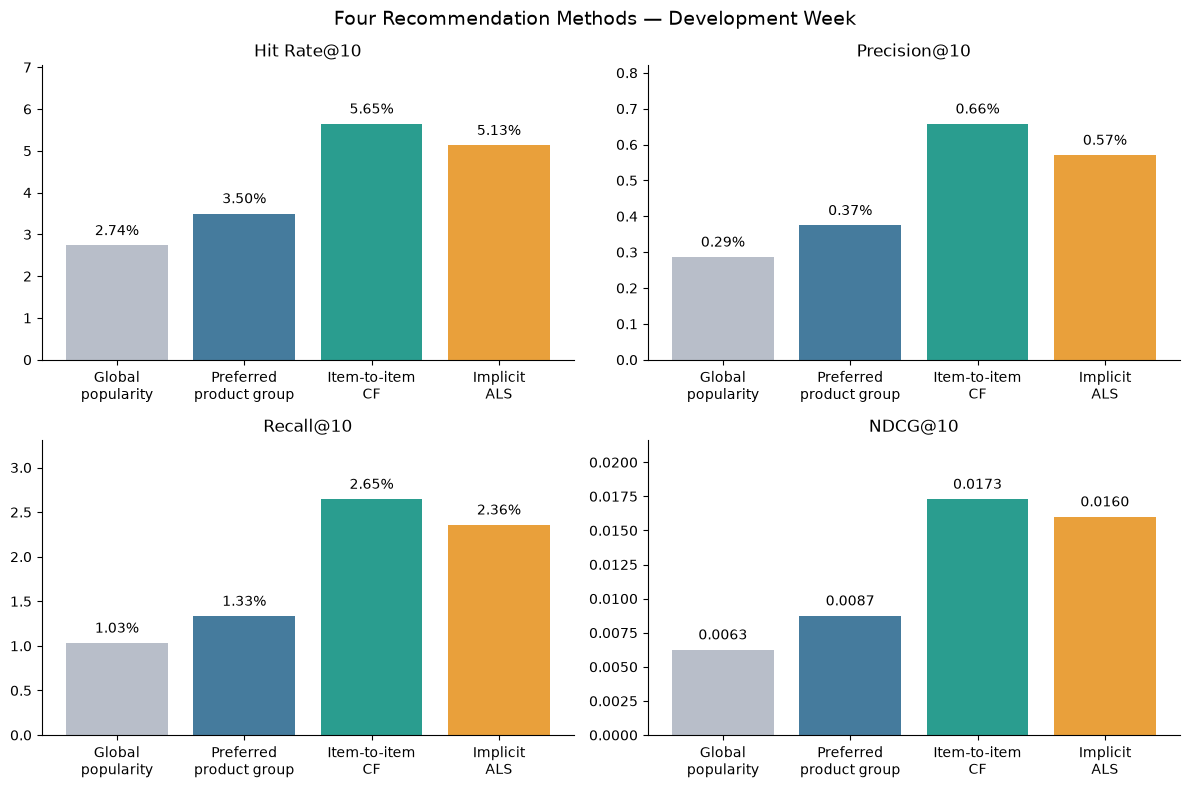

Comparison table and graph saved.


In [18]:
# 1. Match actual purchases with ALS recommendations.
als_customer_metrics = con.execute("""
    SELECT
        actual.customer_id,
        COUNT(*) AS actual_articles,
        COUNT(rec.article_id) AS matching_articles,
        SUM(
            CASE
                WHEN rec.article_id IS NOT NULL
                THEN 1.0 / LOG2(rec.recommendation_rank + 1)
                ELSE 0.0
            END
        ) AS dcg
    FROM recommendation_test_purchases AS actual
    LEFT JOIN als_recommendations AS rec
        ON actual.customer_id = rec.customer_id
       AND actual.article_id = rec.article_id
    GROUP BY actual.customer_id
""").df()

assert set(als_customer_metrics["customer_id"]) == set(
    popularity_customer_metrics["customer_id"]
), "Evaluation customer populations do not match."

# 2. Calculate customer-level metrics.
ideal_dcg_lookup = np.concatenate([
    [0.0],
    np.cumsum(1.0 / np.log2(np.arange(1, top_k + 1) + 1))
])

ideal_match_count = np.minimum(
    als_customer_metrics["actual_articles"].to_numpy(dtype=int),
    top_k
)

als_customer_metrics["hit"] = (
    als_customer_metrics["matching_articles"] > 0
).astype(int)

als_customer_metrics["precision"] = (
    als_customer_metrics["matching_articles"] / top_k
)

als_customer_metrics["recall"] = (
    als_customer_metrics["matching_articles"]
    / als_customer_metrics["actual_articles"]
)

als_customer_metrics["ndcg"] = (
    als_customer_metrics["dcg"]
    / ideal_dcg_lookup[ideal_match_count]
)

als_results = pd.DataFrame([{
    "model": "Implicit ALS",
    "evaluated_customers": len(als_customer_metrics),
    "top_k": top_k,
    "hit_rate": als_customer_metrics["hit"].mean(),
    "precision": als_customer_metrics["precision"].mean(),
    "recall": als_customer_metrics["recall"].mean(),
    "ndcg": als_customer_metrics["ndcg"].mean(),
}])

# 3. Rebuild the comparison so rerunning does not duplicate results.
recommendation_comparison = pd.concat(
    [
        popularity_results,
        category_results,
        item_cf_results,
        als_results
    ],
    ignore_index=True
)

display(
    recommendation_comparison.style.format({
        "evaluated_customers": "{:,}",
        "hit_rate": "{:.2%}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "ndcg": "{:.4f}",
    })
)

als_hit = float(als_results.iloc[0]["hit_rate"])
item_cf_hit = float(item_cf_results.iloc[0]["hit_rate"])

print(
    "ALS vs item-to-item CF — Hit Rate change: "
    f"{100 * (als_hit - item_cf_hit):+.2f} percentage points"
)

# 4. Plot each metric separately.
metric_specs = [
    ("hit_rate", f"Hit Rate@{top_k}", 100, "%"),
    ("precision", f"Precision@{top_k}", 100, "%"),
    ("recall", f"Recall@{top_k}", 100, "%"),
    ("ndcg", f"NDCG@{top_k}", 1, ""),
]

labels = [
    "Global\npopularity",
    "Preferred\nproduct group",
    "Item-to-item\nCF",
    "Implicit\nALS"
]

colors = ["#B8BEC9", "#457B9D", "#2A9D8F", "#E9A03B"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (metric, title, scale, suffix) in zip(axes.flat, metric_specs):
    values = recommendation_comparison[metric].to_numpy() * scale
    bars = ax.bar(labels, values, color=colors)

    for bar, value in zip(bars, values):
        label = f"{value:.2f}{suffix}" if suffix else f"{value:.4f}"
        ax.annotate(
            label,
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom"
        )

    ax.set_title(title)
    ax.set_ylim(0, max(float(values.max()) * 1.25, 0.001))
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Four Recommendation Methods — Development Week",
    fontsize=14
)
fig.tight_layout()

fig.savefig(
    recommendation_report_dir / "four_model_recommendation_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

recommendation_comparison.to_csv(
    recommendation_report_dir / "four_model_recommendation_metrics.csv",
    index=False
)

print("Comparison table and graph saved.")

### Findings: Comparison of Four Recommendation Methods

Item-to-item collaborative filtering achieved the highest values across all
four development metrics, followed by implicit ALS, preferred-group popularity,
and global popularity.

ALS achieved a Hit Rate@10 of 5.13%, compared with 5.65% for item-to-item CF.
The result applies to the configurations tested; it does not establish that
item-to-item methods always outperform ALS.

Item-to-item CF is provisionally selected for later-period evaluation.
Its performance on this development week is not an unbiased estimate of
final performance because this period was used to compare methods.

In [19]:
from datetime import date, timedelta

final_recommendation_cutoff = "2020-01-31"
final_evaluation_days = 7

final_cutoff = date.fromisoformat(final_recommendation_cutoff)
final_outcome_end = final_cutoff + timedelta(days=final_evaluation_days)

# Check that the source extends through the intended outcome window.
final_period_coverage = con.execute(f"""
    SELECT
        MIN(t_dat) AS dataset_start,
        MAX(t_dat) AS dataset_end,
        DATE '{final_recommendation_cutoff}' AS feature_cutoff,
        DATE '{final_cutoff + timedelta(days=1)}' AS outcome_start,
        DATE '{final_outcome_end}' AS outcome_end,
        MAX(t_dat) >= DATE '{final_outcome_end}'
            AS outcome_end_is_covered
    FROM transactions
""").df()

display(final_period_coverage)

if not bool(final_period_coverage.loc[0, "outcome_end_is_covered"]):
    raise ValueError("The dataset does not extend through the outcome window.")

# Use separate tables to preserve the development-period results.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE final_recommendation_eligible_customers AS
    SELECT DISTINCT customer_id
    FROM transactions
    WHERE t_dat <= DATE '{final_recommendation_cutoff}'
      AND customer_id IS NOT NULL
""")

con.execute(f"""
    CREATE OR REPLACE TEMP TABLE final_recommendation_test_purchases AS
    SELECT DISTINCT
        t.customer_id,
        t.article_id
    FROM transactions AS t
    INNER JOIN final_recommendation_eligible_customers AS e
        ON t.customer_id = e.customer_id
    WHERE t.t_dat > DATE '{final_recommendation_cutoff}'
      AND t.t_dat <= DATE '{final_outcome_end}'
      AND t.article_id IS NOT NULL
""")

final_period_summary = con.execute("""
    SELECT
        COUNT(DISTINCT customer_id) AS evaluated_customers,
        COUNT(*) AS distinct_customer_article_outcomes,
        COUNT(DISTINCT article_id) AS purchased_articles
    FROM final_recommendation_test_purchases
""").df()

display(final_period_summary)

assert int(final_period_summary.loc[0, "evaluated_customers"]) > 0

print("Later-period evaluation population is ready.")
print("No later-period recommendation metrics have been calculated yet.")

,dataset_start,dataset_end,feature_cutoff,outcome_start,outcome_end,outcome_end_is_covered
0,2018-09-20,2020-09-22,2020-01-31,2020-02-01,2020-02-07,True


,evaluated_customers,distinct_customer_article_outcomes,purchased_articles
0,64178,200298,20447


Later-period evaluation population is ready.
No later-period recommendation metrics have been calculated yet.


## 6. Later-Period Evaluation: Rebuilding the Selected Model

The selected item-to-item method is rebuilt using information available
by 31 January 2020.

Fixed settings:
- Historical interactions: preceding 90 days.
- Popularity fallback: preceding 28 days.
- Minimum shared customers: 3.
- Similarity shrinkage: 10.
- Neighbors per article: 20.
- Recommendations per customer: 10.

Article relationships are learned from all customers in the historical window.
Purchases from 1–7 February are reserved for evaluation and do not influence
similarity scores or popularity rankings.

This evaluates the selected method after refreshing its historical data.

In [20]:
import time

# Fixed configuration selected before examining later-period metrics.
final_cf_config = {
    "history_days": 90,
    "popularity_days": 28,
    "minimum_shared_customers": 3,
    "similarity_shrinkage": 10.0,
    "neighbors_per_article": 20,
    "top_k": 10,
}

started = time.perf_counter()

# 1. Historical interactions: one row per customer–article pair.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE final_cf_interactions AS
    SELECT
        customer_id,
        article_id,
        COUNT(*) AS purchase_records,
        MAX(t_dat) AS last_purchase_date
    FROM transactions
    WHERE t_dat > DATE '{final_recommendation_cutoff}'
                       - INTERVAL {final_cf_config["history_days"]} DAY
      AND t_dat <= DATE '{final_recommendation_cutoff}'
      AND customer_id IS NOT NULL
      AND article_id IS NOT NULL
    GROUP BY customer_id, article_id
""")

# 2. Refresh global popularity for the baseline and fallback.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE final_popularity_ranking AS
    WITH article_counts AS (
        SELECT
            article_id,
            COUNT(*) AS purchase_records
        FROM transactions
        WHERE t_dat > DATE '{final_recommendation_cutoff}'
                           - INTERVAL {final_cf_config["popularity_days"]} DAY
          AND t_dat <= DATE '{final_recommendation_cutoff}'
          AND article_id IS NOT NULL
        GROUP BY article_id
    )
    SELECT
        *,
        ROW_NUMBER() OVER (
            ORDER BY purchase_records DESC, article_id
        ) AS recommendation_rank
    FROM article_counts
""")

# 3. Article support from the same historical interactions.
con.execute("""
    CREATE OR REPLACE TEMP TABLE final_cf_article_support AS
    SELECT
        article_id,
        COUNT(*) AS customer_count
    FROM final_cf_interactions
    GROUP BY article_id
""")

print("Counting later-cutoff historical article relationships...")

# 4. Count shared customers, using only historical purchases.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE final_cf_pair_counts AS
    SELECT
        a.article_id AS article_a,
        b.article_id AS article_b,
        COUNT(*) AS shared_customers
    FROM final_cf_interactions AS a
    INNER JOIN final_cf_interactions AS b
        ON a.customer_id = b.customer_id
       AND a.article_id < b.article_id
    GROUP BY a.article_id, b.article_id
    HAVING COUNT(*) >= {final_cf_config["minimum_shared_customers"]}
""")

# 5. Apply exactly the same similarity formula.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE final_cf_pair_scores AS
    SELECT
        p.article_a,
        p.article_b,
        p.shared_customers,
        (
            p.shared_customers::DOUBLE
            / SQRT(
                a.customer_count::DOUBLE * b.customer_count::DOUBLE
            )
        ) * (
            p.shared_customers::DOUBLE
            / (
                p.shared_customers
                + {final_cf_config["similarity_shrinkage"]}
            )
        ) AS similarity_score
    FROM final_cf_pair_counts AS p
    INNER JOIN final_cf_article_support AS a
        ON p.article_a = a.article_id
    INNER JOIN final_cf_article_support AS b
        ON p.article_b = b.article_id
""")

# 6. Retain up to 20 neighbors per source article.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE final_item_neighbors AS
    WITH directed_pairs AS (
        SELECT
            article_a AS source_article_id,
            article_b AS neighbor_article_id,
            shared_customers,
            similarity_score
        FROM final_cf_pair_scores

        UNION ALL

        SELECT
            article_b AS source_article_id,
            article_a AS neighbor_article_id,
            shared_customers,
            similarity_score
        FROM final_cf_pair_scores
    ),
    ranked AS (
        SELECT
            *,
            ROW_NUMBER() OVER (
                PARTITION BY source_article_id
                ORDER BY
                    similarity_score DESC,
                    shared_customers DESC,
                    neighbor_article_id
            ) AS neighbor_rank
        FROM directed_pairs
    )
    SELECT *
    FROM ranked
    WHERE neighbor_rank <= {final_cf_config["neighbors_per_article"]}
""")

# 7. Summarize training data and model size.
final_model_summary = con.execute("""
    SELECT
        (SELECT COUNT(*) FROM final_cf_interactions)
            AS historical_customer_article_pairs,
        (SELECT COUNT(DISTINCT customer_id) FROM final_cf_interactions)
            AS historical_customers,
        (SELECT COUNT(*) FROM final_cf_article_support)
            AS historical_articles,
        (SELECT MAX(last_purchase_date) FROM final_cf_interactions)
            AS latest_training_purchase,
        COUNT(*) AS directed_neighbor_links,
        COUNT(DISTINCT source_article_id) AS articles_with_neighbors,
        ROUND(AVG(similarity_score), 4) AS mean_similarity
    FROM final_item_neighbors
""").df()

display(final_model_summary)

assert int(final_model_summary.loc[0, "directed_neighbor_links"]) > 0
assert (
    pd.Timestamp(final_model_summary.loc[0, "latest_training_purchase"])
    <= pd.Timestamp(final_recommendation_cutoff)
)

final_cf_training_seconds = time.perf_counter() - started

print(f"Model rebuilt in {final_cf_training_seconds:,.1f} seconds.")
print("Training cutoff:", final_recommendation_cutoff)
print("February evaluation purchases were not used to build the model.")

Counting later-cutoff historical article relationships...


,historical_customer_article_pairs,historical_customers,historical_articles,latest_training_purchase,directed_neighbor_links,articles_with_neighbors,mean_similarity
0,2892128,505599,40721,2020-01-31,208357,17615,0.0181


Model rebuilt in 12.4 seconds.
Training cutoff: 2020-01-31
February evaluation purchases were not used to build the model.


In [21]:
final_top_k = final_cf_config["top_k"]

# 1. Score candidates for the later-period evaluation customers.
con.execute("""
    CREATE OR REPLACE TEMP TABLE final_cf_candidate_scores AS
    SELECT
        h.customer_id,
        n.neighbor_article_id AS article_id,
        SUM(n.similarity_score) AS recommendation_score
    FROM final_cf_interactions AS h
    INNER JOIN (
        SELECT DISTINCT customer_id
        FROM final_recommendation_test_purchases
    ) AS e
        ON h.customer_id = e.customer_id
    INNER JOIN final_item_neighbors AS n
        ON h.article_id = n.source_article_id
    GROUP BY h.customer_id, n.neighbor_article_id
""")

# 2. Rank personalized candidates and add popularity fallback.
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE final_cf_recommendations AS
    WITH evaluation_customers AS (
        SELECT DISTINCT customer_id
        FROM final_recommendation_test_purchases
    ),
    personalized AS (
        SELECT
            customer_id,
            article_id,
            recommendation_score,
            ROW_NUMBER() OVER (
                PARTITION BY customer_id
                ORDER BY recommendation_score DESC, article_id
            ) AS candidate_rank
        FROM final_cf_candidate_scores
        QUALIFY candidate_rank <= {final_top_k}
    ),
    candidates AS (
        SELECT
            customer_id,
            article_id,
            recommendation_score,
            0 AS source_priority,
            candidate_rank AS source_rank,
            'Item-to-item similarity' AS recommendation_source
        FROM personalized

        UNION ALL

        SELECT
            e.customer_id,
            p.article_id,
            0.0 AS recommendation_score,
            1 AS source_priority,
            p.recommendation_rank AS source_rank,
            'Global popularity fallback' AS recommendation_source
        FROM evaluation_customers AS e
        CROSS JOIN (
            SELECT article_id, recommendation_rank
            FROM final_popularity_ranking
            WHERE recommendation_rank <= {final_top_k}
        ) AS p
    ),
    deduplicated AS (
        SELECT *
        FROM candidates
        QUALIFY ROW_NUMBER() OVER (
            PARTITION BY customer_id, article_id
            ORDER BY source_priority, source_rank
        ) = 1
    ),
    ranked AS (
        SELECT
            customer_id,
            article_id,
            recommendation_score,
            recommendation_source,
            ROW_NUMBER() OVER (
                PARTITION BY customer_id
                ORDER BY source_priority, source_rank, article_id
            ) AS recommendation_rank
        FROM deduplicated
    )
    SELECT *
    FROM ranked
    WHERE recommendation_rank <= {final_top_k}
""")

# 3. Validate recommendation lists.
final_list_check = con.execute(f"""
    WITH customer_lists AS (
        SELECT
            customer_id,
            COUNT(*) AS list_size,
            COUNT(DISTINCT article_id) AS unique_articles,
            COUNT(*) FILTER (
                WHERE recommendation_source = 'Item-to-item similarity'
            ) AS personalized_positions
        FROM final_cf_recommendations
        GROUP BY customer_id
    )
    SELECT
        COUNT(*) AS customers,
        SUM(list_size) AS recommendation_rows,
        MIN(list_size) AS minimum_list_size,
        MAX(list_size) AS maximum_list_size,
        COUNT(*) FILTER (
            WHERE list_size != {final_top_k}
               OR unique_articles != {final_top_k}
        ) AS invalid_lists,
        COUNT(*) FILTER (
            WHERE personalized_positions > 0
        ) AS customers_with_personalized_recommendations,
        COUNT(*) FILTER (
            WHERE personalized_positions = 0
        ) AS customers_with_only_fallback
    FROM customer_lists
""").df()

display(final_list_check)

expected_final_customers = con.execute("""
    SELECT COUNT(DISTINCT customer_id)
    FROM final_recommendation_test_purchases
""").fetchone()[0]

assert int(final_list_check.loc[0, "customers"]) == expected_final_customers
assert int(final_list_check.loc[0, "invalid_lists"]) == 0

print("Later-period recommendations are ready.")

,customers,recommendation_rows,minimum_list_size,maximum_list_size,invalid_lists,customers_with_personalized_recommendations,customers_with_only_fallback
0,64178,641780.0,10,10,0,50728,13450


Later-period recommendations are ready.


### Later-Period Recommendation Results

The selected item-to-item method and refreshed popularity baseline are
evaluated against purchases from 1–7 February 2020.

Both methods use information available by 31 January and are evaluated
on the same 64,178 existing customers who purchased during the outcome week.

Customers receiving fallback remain included. Metrics are averaged equally
across customers.

Model settings were fixed before examining these later-period metrics.
This evaluation measures purchase relevance among returning customers,
not campaign impact or performance across every possible future period.

,model,evaluated_customers,top_k,hit_rate,precision,recall,ndcg
0,Recent popularity,"64,178",10,3.86%,0.44%,1.43%,0.0092
1,Item-to-item collaborative filtering,"64,178",10,5.86%,0.71%,2.74%,0.0182


Later-period Hit Rate improvement: +2.00 percentage points
Hit Rate relative to popularity: 1.52x


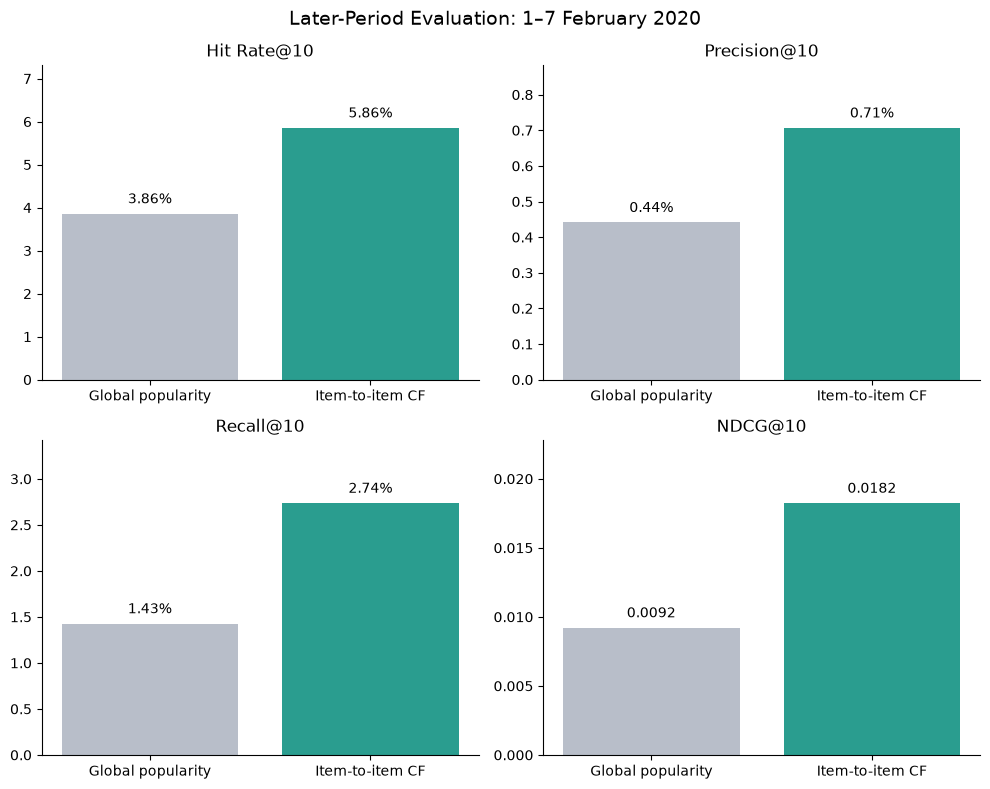

Later-period metrics and graph saved.


In [22]:
# 1. Calculate customer-level matches for both methods.
final_popularity_customer_metrics = con.execute(f"""
    SELECT
        actual.customer_id,
        COUNT(*) AS actual_articles,
        COUNT(rec.article_id) AS matching_articles,
        SUM(
            CASE WHEN rec.article_id IS NOT NULL
                THEN 1.0 / LOG2(rec.recommendation_rank + 1)
                ELSE 0.0
            END
        ) AS dcg
    FROM final_recommendation_test_purchases AS actual
    LEFT JOIN (
        SELECT article_id, recommendation_rank
        FROM final_popularity_ranking
        WHERE recommendation_rank <= {final_top_k}
    ) AS rec
        ON actual.article_id = rec.article_id
    GROUP BY actual.customer_id
""").df()

final_cf_customer_metrics = con.execute("""
    SELECT
        actual.customer_id,
        COUNT(*) AS actual_articles,
        COUNT(rec.article_id) AS matching_articles,
        SUM(
            CASE WHEN rec.article_id IS NOT NULL
                THEN 1.0 / LOG2(rec.recommendation_rank + 1)
                ELSE 0.0
            END
        ) AS dcg
    FROM final_recommendation_test_purchases AS actual
    LEFT JOIN final_cf_recommendations AS rec
        ON actual.customer_id = rec.customer_id
       AND actual.article_id = rec.article_id
    GROUP BY actual.customer_id
""").df()

assert set(final_popularity_customer_metrics["customer_id"]) == set(
    final_cf_customer_metrics["customer_id"]
)

# 2. Calculate identical metrics for each method.
ideal_dcg_lookup = np.concatenate([
    [0.0],
    np.cumsum(1.0 / np.log2(np.arange(1, final_top_k + 1) + 1))
])

final_result_rows = []

for model_name, customer_metrics in [
    ("Recent popularity", final_popularity_customer_metrics),
    ("Item-to-item collaborative filtering", final_cf_customer_metrics),
]:
    ideal_count = np.minimum(
        customer_metrics["actual_articles"].to_numpy(dtype=int),
        final_top_k
    )

    customer_metrics["hit"] = (
        customer_metrics["matching_articles"] > 0
    ).astype(int)

    customer_metrics["precision"] = (
        customer_metrics["matching_articles"] / final_top_k
    )

    customer_metrics["recall"] = (
        customer_metrics["matching_articles"]
        / customer_metrics["actual_articles"]
    )

    customer_metrics["ndcg"] = (
        customer_metrics["dcg"] / ideal_dcg_lookup[ideal_count]
    )

    final_result_rows.append({
        "model": model_name,
        "evaluated_customers": len(customer_metrics),
        "top_k": final_top_k,
        "hit_rate": customer_metrics["hit"].mean(),
        "precision": customer_metrics["precision"].mean(),
        "recall": customer_metrics["recall"].mean(),
        "ndcg": customer_metrics["ndcg"].mean(),
    })

final_recommendation_results = pd.DataFrame(final_result_rows)

display(
    final_recommendation_results.style.format({
        "evaluated_customers": "{:,}",
        "hit_rate": "{:.2%}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "ndcg": "{:.4f}",
    })
)

baseline_hit = float(final_recommendation_results.iloc[0]["hit_rate"])
selected_hit = float(final_recommendation_results.iloc[1]["hit_rate"])

print(
    "Later-period Hit Rate improvement: "
    f"{100 * (selected_hit - baseline_hit):+.2f} percentage points"
)

if baseline_hit > 0:
    print(f"Hit Rate relative to popularity: {selected_hit / baseline_hit:.2f}x")

# 3. Plot the later-period comparison.
metric_specs = [
    ("hit_rate", f"Hit Rate@{final_top_k}", 100, "%"),
    ("precision", f"Precision@{final_top_k}", 100, "%"),
    ("recall", f"Recall@{final_top_k}", 100, "%"),
    ("ndcg", f"NDCG@{final_top_k}", 1, ""),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (metric, title, scale, suffix) in zip(axes.flat, metric_specs):
    values = final_recommendation_results[metric].to_numpy() * scale

    bars = ax.bar(
        ["Global popularity", "Item-to-item CF"],
        values,
        color=["#B8BEC9", "#2A9D8F"]
    )

    for bar, value in zip(bars, values):
        label = f"{value:.2f}{suffix}" if suffix else f"{value:.4f}"
        ax.annotate(
            label,
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom"
        )

    ax.set_title(title)
    ax.set_ylim(0, max(float(values.max()) * 1.25, 0.001))
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Later-Period Evaluation: 1–7 February 2020", fontsize=14)
fig.tight_layout()

fig.savefig(
    recommendation_report_dir / "final_temporal_recommendation_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# Include dates in the saved results for reproducibility.
final_results_export = final_recommendation_results.assign(
    feature_cutoff=final_recommendation_cutoff,
    outcome_start=str(final_cutoff + timedelta(days=1)),
    outcome_end=str(final_outcome_end)
)

final_results_export.to_csv(
    recommendation_report_dir / "final_temporal_recommendation_metrics.csv",
    index=False
)

print("Later-period metrics and graph saved.")

### Findings: Later-Period Evaluation

On 1–7 February 2020, the selected item-to-item collaborative filtering
method outperformed the refreshed global-popularity baseline across all
four metrics among 64,178 existing customers who purchased during that week.

Hit Rate@10 increased from 3.86% to 5.86%, an improvement of approximately
2 percentage points. Recall@10 increased from 1.43% to 2.74%, and
NDCG@10 increased from 0.0092 to 0.0182.

The method's advantage therefore persisted in a later evaluation window
with fixed settings and refreshed historical data.

Limitations:
- Absolute purchase-match rates remain modest.
- Evaluation includes existing customers who purchased during the outcome week.
- Unpurchased recommendations are not necessarily disliked.
- Inventory availability and recommendation exposure are unavailable.
- Results do not establish incremental sales or campaign effectiveness.
- One later week does not establish performance across all seasons.

Item-to-item collaborative filtering is selected for the recommendation module.

In [23]:
import json
from datetime import datetime, timezone
from pathlib import Path

recommendation_model_dir = (
    project_root / "models" / "recommendations" / final_recommendation_cutoff
)
recommendation_model_dir.mkdir(parents=True, exist_ok=True)

# Save the components needed to reproduce recommendations at this cutoff.
tables_to_save = {
    "item_neighbors.parquet": "final_item_neighbors",
    "customer_article_history.parquet": "final_cf_interactions",
    "popularity_ranking.parquet": "final_popularity_ranking",
    "evaluation_recommendations.parquet": "final_cf_recommendations",
}

saved_rows = []

for filename, table_name in tables_to_save.items():
    output_path = recommendation_model_dir / filename
    sql_path = output_path.as_posix().replace("'", "''")

    con.execute(f"""
        COPY (SELECT * FROM {table_name})
        TO '{sql_path}'
        (FORMAT PARQUET, COMPRESSION ZSTD)
    """)

    original_count = con.execute(
        f"SELECT COUNT(*) FROM {table_name}"
    ).fetchone()[0]

    saved_count = con.execute(
        "SELECT COUNT(*) FROM read_parquet(?)",
        [str(output_path)]
    ).fetchone()[0]

    assert original_count == saved_count, f"Row mismatch: {filename}"

    saved_rows.append({
        "file": filename,
        "verified_rows": saved_count,
        "size_MiB": output_path.stat().st_size / (1024 ** 2)
    })

# Save full-precision evaluation results.
final_results_export.to_csv(
    recommendation_model_dir / "temporal_evaluation_metrics.csv",
    index=False
)

metadata = {
    "model": "Item-to-item collaborative filtering",
    "feature_cutoff": final_recommendation_cutoff,
    "outcome_start": str(final_cutoff + timedelta(days=1)),
    "outcome_end": str(final_outcome_end),
    "configuration": final_cf_config,
    "interaction_definition": "One binary customer-article interaction per window",
    "similarity_formula": (
        "shared_customers / sqrt(customers_A * customers_B) "
        "* shared_customers / (shared_customers + similarity_shrinkage)"
    ),
    "neighbor_order": [
        "similarity_score DESC",
        "shared_customers DESC",
        "neighbor_article_id ASC"
    ],
    "customer_scoring": (
        "Sum neighbor similarity scores across distinct historical articles"
    ),
    "candidate_order": ["summed_similarity DESC", "article_id ASC"],
    "previously_purchased_articles_allowed": True,
    "self_neighbor_links_allowed": False,
    "fallback": (
        "Append global popularity ordered by purchase_records DESC, "
        "article_id ASC; remove duplicate articles; retain top_k"
    ),
    "evaluation_population": (
        "Customers observed by the cutoff who purchased during the outcome week"
    ),
    "evaluation_recommendations_scope": (
        "Historical evaluation cohort only; not all eligible customers"
    ),
    "temporal_metrics": json.loads(
        final_recommendation_results.to_json(orient="records")
    ),
    "limitations": [
        "Scores are not purchase probabilities.",
        "Inventory availability is not modeled.",
        "Offline matches do not measure incremental sales.",
        "Evaluation covers one later week among returning customers."
    ],
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

metadata_path = recommendation_model_dir / "metadata.json"
metadata_path.write_text(
    json.dumps(metadata, indent=2, allow_nan=False),
    encoding="utf-8"
)

display(pd.DataFrame(saved_rows).round(2))
print("Saved recommendation components:", recommendation_model_dir)
print("Saved configuration:", metadata_path)

,file,verified_rows,size_MiB
0,item_neighbors.parquet,208357,2.12
1,customer_article_history.parquet,2892128,59.85
2,popularity_ranking.parquet,29163,0.16
3,evaluation_recommendations.parquet,641780,6.04


Saved recommendation components: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\models\recommendations\2020-01-31
Saved configuration: C:\Users\Admin\Desktop\PROJECTS\Data - science Mini-Project\models\recommendations\2020-01-31\metadata.json


### Verifying Saved-Model Reproducibility

Load the saved recommendation components through a fresh database connection.

Rebuild recommendation lists for a deterministic sample of evaluation customers,
including personalized and fallback-only cases. Compare article IDs, ranks,
sources, and scores against the exported recommendations.

This verifies sampled prediction reproducibility without relying on the
original temporary training tables.

In [24]:
import json
import duckdb
import pandas as pd

saved_metadata = json.loads(
    (recommendation_model_dir / "metadata.json").read_text(encoding="utf-8")
)
saved_top_k = int(saved_metadata["configuration"]["top_k"])

# Separate connection: no access to the notebook's temporary training tables.
verify_con = duckdb.connect()
verify_con.execute("SET memory_limit = '1GB'")
verify_con.execute("SET threads = 2")

try:
    saved_sources = {
        "saved_neighbors": "item_neighbors.parquet",
        "saved_history": "customer_article_history.parquet",
        "saved_popularity": "popularity_ranking.parquet",
        "saved_recommendations": "evaluation_recommendations.parquet",
    }

    for view_name, filename in saved_sources.items():
        path = (recommendation_model_dir / filename).as_posix().replace("'", "''")
        verify_con.execute(f"""
            CREATE VIEW {view_name} AS
            SELECT * FROM read_parquet('{path}')
        """)

    # Up to 100 customers from each source pattern:
    # personalized-only, mixed, or fallback-only.
    verify_con.execute("""
        CREATE TEMP TABLE verification_customers AS
        WITH customer_sources AS (
            SELECT
                customer_id,
                CASE
                    WHEN COUNT(*) FILTER (
                        WHERE recommendation_source = 'Item-to-item similarity'
                    ) = 0 THEN 'Fallback only'
                    WHEN COUNT(*) FILTER (
                        WHERE recommendation_source = 'Global popularity fallback'
                    ) = 0 THEN 'Personalized only'
                    ELSE 'Mixed'
                END AS source_pattern
            FROM saved_recommendations
            GROUP BY customer_id
        )
        SELECT *
        FROM customer_sources
        QUALIFY ROW_NUMBER() OVER (
            PARTITION BY source_pattern ORDER BY customer_id
        ) <= 100
    """)

    # Rebuild candidates from saved history and saved article relationships.
    verify_con.execute(f"""
        CREATE TEMP TABLE reproduced_recommendations AS
        WITH scores AS (
            SELECT
                h.customer_id,
                n.neighbor_article_id AS article_id,
                SUM(n.similarity_score) AS recommendation_score
            FROM saved_history AS h
            INNER JOIN verification_customers AS v
                ON h.customer_id = v.customer_id
            INNER JOIN saved_neighbors AS n
                ON h.article_id = n.source_article_id
            GROUP BY h.customer_id, n.neighbor_article_id
        ),
        personalized AS (
            SELECT
                *,
                ROW_NUMBER() OVER (
                    PARTITION BY customer_id
                    ORDER BY recommendation_score DESC, article_id
                ) AS source_rank
            FROM scores
            QUALIFY source_rank <= {saved_top_k}
        ),
        candidates AS (
            SELECT
                customer_id,
                article_id,
                recommendation_score,
                source_rank,
                0 AS source_priority,
                'Item-to-item similarity' AS recommendation_source
            FROM personalized

            UNION ALL

            SELECT
                v.customer_id,
                p.article_id,
                0.0 AS recommendation_score,
                p.recommendation_rank AS source_rank,
                1 AS source_priority,
                'Global popularity fallback' AS recommendation_source
            FROM verification_customers AS v
            CROSS JOIN (
                SELECT article_id, recommendation_rank
                FROM saved_popularity
                WHERE recommendation_rank <= {saved_top_k}
            ) AS p
        ),
        deduplicated AS (
            SELECT *
            FROM candidates
            QUALIFY ROW_NUMBER() OVER (
                PARTITION BY customer_id, article_id
                ORDER BY source_priority, source_rank
            ) = 1
        )
        SELECT
            customer_id,
            article_id,
            recommendation_score,
            recommendation_source,
            ROW_NUMBER() OVER (
                PARTITION BY customer_id
                ORDER BY source_priority, source_rank, article_id
            ) AS recommendation_rank
        FROM deduplicated
        QUALIFY recommendation_rank <= {saved_top_k}
    """)

    # Compare by customer and rank, including missing/extra positions.
    verification_result = verify_con.execute("""
        WITH expected AS (
            SELECT r.*
            FROM saved_recommendations AS r
            INNER JOIN verification_customers AS v
                ON r.customer_id = v.customer_id
        )
        SELECT
            COUNT(*) AS compared_positions,
            COUNT(*) FILTER (
                WHERE e.customer_id IS NULL OR r.customer_id IS NULL
            ) AS missing_or_extra_positions,
            COUNT(*) FILTER (
                WHERE e.article_id IS DISTINCT FROM r.article_id
            ) AS article_mismatches,
            COUNT(*) FILTER (
                WHERE e.recommendation_source
                    IS DISTINCT FROM r.recommendation_source
            ) AS source_mismatches,
            COUNT(*) FILTER (
                WHERE e.recommendation_score IS NULL
                   OR r.recommendation_score IS NULL
                   OR NOT ISFINITE(e.recommendation_score)
                   OR NOT ISFINITE(r.recommendation_score)
                   OR ABS(e.recommendation_score - r.recommendation_score)
                      > 1e-10 + 1e-8 * ABS(e.recommendation_score)
            ) AS score_mismatches
        FROM expected AS e
        FULL OUTER JOIN reproduced_recommendations AS r
            ON e.customer_id = r.customer_id
           AND e.recommendation_rank = r.recommendation_rank
    """).df()

    display(verify_con.execute("""
        SELECT source_pattern, COUNT(*) AS sampled_customers
        FROM verification_customers
        GROUP BY source_pattern
        ORDER BY source_pattern
    """).df())

    display(verification_result)

    mismatch_columns = [
        "missing_or_extra_positions",
        "article_mismatches",
        "source_mismatches",
        "score_mismatches",
    ]

    assert int(verification_result.loc[0, "compared_positions"]) > 0
    assert (verification_result[mismatch_columns].iloc[0] == 0).all(), (
        "Reproduction mismatch detected. Review the output before proceeding."
    )

    verification_result.to_csv(
        recommendation_report_dir / "saved_model_reproduction_check.csv",
        index=False
    )

    print("PASS: saved components reproduce the sampled recommendation lists.")

finally:
    verify_con.close()

,source_pattern,sampled_customers
0,Fallback only,100
1,Mixed,100
2,Personalized only,100


,compared_positions,missing_or_extra_positions,article_mismatches,source_mismatches,score_mismatches
0,3000,0,0,0,0


PASS: saved components reproduce the sampled recommendation lists.


### Recommendation Module Summary

Four methods were compared during development:
1. Global recent popularity
2. Preferred-product-group popularity
3. Item-to-item collaborative filtering
4. Implicit ALS

Item-to-item collaborative filtering performed best across the four
development metrics and was selected for later-period evaluation.

During 1–7 February 2020:
- Hit Rate@10: 5.86%, compared with 3.86% for global popularity.
- Precision@10: 0.71%, compared with 0.44%.
- Recall@10: 2.74%, compared with 1.43%.
- NDCG@10: 0.0182, compared with 0.0092.

The selected model's components, configuration, evaluation metrics, and
recommendation lists were saved.

A fresh database connection reproduced all 3,000 sampled recommendation
positions across 300 customers, with no article, source, or score mismatches.

The module supports historical personalized product recommendations.
Its offline results do not establish incremental sales, and recommendations
do not account for current inventory availability.